# Iran's 2010 Energy Subsidy Reform — Replication & Continuous-Dose Extension

**Replication and extension of Zarepour & Wagner (2023, *Energy Economics* 124, 106762), “How manufacturing firms respond to energy subsidy reforms? An impact assessment of the Iranian Energy Subsidy Reform.”**

**Project extension:** *“Direct vs. Indirect Exposure: A Continuous-Dose Reassessment of Iran's 2010 Energy Subsidy Reform.”*

This notebook combines three pieces of the project's Python code into one runnable, documented workflow:

| Part | Source file | What it does |
|---|---|---|
| 1 | `stats_lite.py` | A dependency-light statistics engine that reproduces Stata's `areg ..., absorb(id) vce(cluster id)` logic: OLS with an absorbed fixed effect, clustered sandwich covariance, small-sample correction, distribution functions, and Wald tests. |
| 2 | `codes_final_python.py` | The **paper replication**: a Python translation of the original Stata do-file (`codes_final.do`), reproducing Tables 5–8 and the appendix tables via `statsmodels`/`scipy`. |
| 3 | `extension_analysis.py` | The **extension**: constructs continuous measures of direct and indirect input exposure and re-estimates the difference-in-differences design using dose-response DiD, an event study, alternative inference schemes, a direct-vs-indirect horse race, and adjustment-margin regressions. |

### How to use this notebook
1. Run the notebook from the repository root, so that the data is found at `data/mydata.xlsx`.
2. Run the cells from top to bottom. Part 1 defines the shared statistics engine. Part 2 reproduces the paper's regressions; Part 3 performs the project extension.
3. Part 3 includes a **replication gate**: before the extension results are used, the custom statistics engine must reproduce the paper's Table 5, Panel C coefficients and standard errors within a small numerical tolerance.
4. The notebook writes regression tables to `results/` and saves the extension figures to `figures/`.


## Part 1 — Statistics engine (`stats_lite.py`)

Minimal, dependency-light re-implementation of the statistical primitives needed for this project's fixed-effects / clustered-SE regressions, using only `numpy`, `pandas`, and `mpmath`.

It reproduces, from scratch:
- **OLS** with an absorbed fixed effect (via within-group demeaning) and a **clustered sandwich covariance**, using Stata's `areg`-style small-sample correction:

$$
V = \underbrace{\frac{G}{G-1}\cdot\frac{N-1}{N-k-\text{absorbed\_df}}}_{\text{small-sample correction}} \; (X'X)^{-1}\Big[\textstyle\sum_g X_g'e_ge_g'X_g\Big](X'X)^{-1}
$$

- **Student-*t*** and **F** distribution tail probabilities, computed via the regularized incomplete beta function (`mpmath.betainc`) instead of `scipy.stats`.
- One-way and two-way **cluster-robust** covariance (Cameron–Gelbach–Miller 2008 style).
- Joint **Wald tests** and pairwise coefficient-difference tests.

All formulas are cross-checked against textbook definitions and against `statsmodels`' `OLS(...).fit(cov_type="cluster", ...)` output (see the replication gate in Part 3).

In [1]:
"""
stats_lite.py
==============
Minimal, dependency-light re-implementation of the statistical primitives
needed for this project's fixed-effects / clustered-SE regressions.

This module provides a transparent, dependency-light implementation of the
statistics needed by the extension: OLS, clustered sandwich covariance with
Stata's areg-style small-sample correction, and Student-t / F distribution
tail probabilities, using only numpy, pandas, and mpmath.

All formulas are cross-checked against textbook definitions used by
Stata's `areg ..., absorb(id) vce(cluster id)` and statsmodels'
`OLS(...).fit(cov_type="cluster", cov_kwds={"use_correction": True,
"df_correction": True})`, which is what codes_final_python.py's areg()
helper calls. See derivation in comments below.
"""

from __future__ import annotations

import math
from dataclasses import dataclass, field
from typing import Sequence

import numpy as np
import pandas as pd
import mpmath as mp

In [2]:
mp.mp.dps = 40  # ample precision for tail probabilities

In [3]:
# -----------------------------------------------------------------------
# Distribution helpers (numpy/mpmath only, no scipy)
# -----------------------------------------------------------------------
def t_sf(t: float, df: float) -> float:
    """One-sided survival function P(T > t) for Student-t with `df` dof."""
    if df <= 0 or not np.isfinite(t):
        return float("nan")
    t = float(t)
    if t == 0:
        return 0.5
    x = df / (df + t * t)
    val = 0.5 * mp.betainc(df / 2.0, 0.5, 0, x, regularized=True)
    val = float(val)
    return val if t > 0 else 1.0 - val


def t_two_sided_p(t: float, df: float) -> float:
    """Two-sided p-value for a t statistic."""
    return 2.0 * t_sf(abs(t), df)


def t_ppf(p: float, df: float, lo: float = 0.0, hi: float = 1000.0) -> float:
    """Inverse CDF (quantile) of Student-t via bisection on the tail fn.

    Solves for t such that P(T > t) = 1 - p (i.e. the usual `ppf(p)`).
    """
    target = 1.0 - p
    # bisection on t_sf(t, df), which is monotonically decreasing in t
    a, b = lo, hi
    fa = t_sf(a, df) - target
    fb = t_sf(b, df) - target
    if fa == 0:
        return a
    for _ in range(200):
        mid = (a + b) / 2.0
        fm = t_sf(mid, df) - target
        if abs(fm) < 1e-12 or (b - a) < 1e-12:
            return mid
        if (fa < 0) == (fm < 0):
            a, fa = mid, fm
        else:
            b, fb = mid, fm
    return (a + b) / 2.0


def f_sf(f: float, df1: float, df2: float) -> float:
    """Survival function P(F > f) for the F(df1, df2) distribution."""
    if f <= 0:
        return 1.0
    x = df2 / (df2 + df1 * f)
    val = mp.betainc(df2 / 2.0, df1 / 2.0, 0, x, regularized=True)
    return float(val)

In [4]:
# -----------------------------------------------------------------------
# Ordered full-rank column selection (same logical rule as the original
# implementation, but using incremental orthogonalization for speed)
# -----------------------------------------------------------------------
def ordered_full_rank_columns(X: pd.DataFrame, tolerance: float = 1e-10):
    """
    Keep the first linearly independent columns in their original order.

    The original implementation repeatedly called ``np.linalg.matrix_rank``
    after adding each candidate column. That is exact but unnecessarily slow
    for the high-dimensional ISIC2×year and province×year dummy sets used in
    the extension. Two-pass modified Gram-Schmidt applies the same ordered
    independence rule incrementally and is much faster for these sparse dummy
    designs.
    """
    A = X.to_numpy(dtype=float)
    kept_idx: list[int] = []
    kept: list[str] = []
    dropped: list[str] = []
    Q = np.empty((A.shape[0], 0), dtype=float)

    for j, column in enumerate(X.columns):
        v = A[:, j].copy()
        if Q.shape[1]:
            # Re-orthogonalize once for numerical stability.
            v -= Q @ (Q.T @ v)
            v -= Q @ (Q.T @ v)
        norm_v = float(np.linalg.norm(v))
        if norm_v > tolerance:
            kept_idx.append(j)
            kept.append(column)
            Q = np.column_stack((Q, v / norm_v))
        else:
            dropped.append(column)

    return kept, dropped


In [5]:
# -----------------------------------------------------------------------
# Core regression result container
# -----------------------------------------------------------------------
@dataclass
class RegResult:
    label: str
    outcome: str
    nobs: int
    n_clusters: int
    k: int
    absorbed_df: int
    df_resid: int
    params: pd.Series
    se: pd.Series
    t: pd.Series
    p: pd.Series
    ci_low: pd.Series
    ci_high: pd.Series
    cov: pd.DataFrame
    within_r2: float
    used: list = field(default_factory=list)
    dropped: list = field(default_factory=list)

    def row(self, variable: str) -> dict:
        return {
            "label": self.label,
            "outcome": self.outcome,
            "variable": variable,
            "coefficient": float(self.params[variable]),
            "std_error": float(self.se[variable]),
            "t_stat": float(self.t[variable]),
            "p_value": float(self.p[variable]),
            "ci_95_low": float(self.ci_low[variable]),
            "ci_95_high": float(self.ci_high[variable]),
            "nobs": self.nobs,
            "n_clusters": self.n_clusters,
            "df_resid": self.df_resid,
            "within_r2": self.within_r2,
        }


def ols_cluster(
    y: np.ndarray,
    X: pd.DataFrame,
    cluster: np.ndarray,
    *,
    absorbed_df: int = 0,
    label: str = "",
    outcome: str = "",
) -> RegResult:
    """
    OLS with a Stata areg-style clustered sandwich covariance.

    Correction factor derivation (matches codes_final_python.py's areg()
    output to full numerical precision, verified against Stata areg,
    vce(cluster) small-sample adjustment):

        base sandwich:      V0 = (X'X)^-1 [sum_g X_g' e_g e_g' X_g] (X'X)^-1
        statsmodels factor:  G/(G-1) * (N-1)/(N-k)
        areg absorbed-FE factor (extra): (N-k)/(N-k-absorbed_df)
        combined:            G/(G-1) * (N-1)/(N-k-absorbed_df)

    where N = nobs, k = number of regressors (used, full-rank columns),
    G = number of clusters, absorbed_df = (#absorbed FE levels - 1).
    """
    used, dropped = ordered_full_rank_columns(X)
    Xu = X[used].to_numpy(dtype=float)
    yv = np.asarray(y, dtype=float)
    n, k = Xu.shape
    XtX = Xu.T @ Xu
    XtX_inv = np.linalg.pinv(XtX)
    beta = XtX_inv @ (Xu.T @ yv)
    resid = yv - Xu @ beta

    groups = pd.Series(cluster).to_numpy()
    uniq_groups = np.unique(groups)
    G = len(uniq_groups)
    df_resid = n - k - absorbed_df

    meat = np.zeros((k, k))
    for g in uniq_groups:
        mask = groups == g
        Xg = Xu[mask]
        eg = resid[mask]
        score = Xg.T @ eg
        meat += np.outer(score, score)

    V0 = XtX_inv @ meat @ XtX_inv
    correction = (G / (G - 1)) * ((n - 1) / df_resid)
    V = V0 * correction

    se = np.sqrt(np.diag(V))
    tvals = beta / se
    dfree = G - 1
    pvals = np.array([t_two_sided_p(tv, dfree) for tv in tvals])
    crit = t_ppf(0.975, dfree)
    ci_low = beta - crit * se
    ci_high = beta + crit * se

    ssr = float(resid @ resid)
    tss = float(yv @ yv)  # centered because within-transformed (mean 0)
    within_r2 = np.nan if tss <= 0 else 1.0 - ssr / tss

    params = pd.Series(beta, index=used)
    se_s = pd.Series(se, index=used)
    t_s = pd.Series(tvals, index=used)
    p_s = pd.Series(pvals, index=used)
    ci_low_s = pd.Series(ci_low, index=used)
    ci_high_s = pd.Series(ci_high, index=used)
    cov_df = pd.DataFrame(V, index=used, columns=used)

    return RegResult(
        label=label,
        outcome=outcome,
        nobs=n,
        n_clusters=G,
        k=k,
        absorbed_df=absorbed_df,
        df_resid=df_resid,
        params=params,
        se=se_s,
        t=t_s,
        p=p_s,
        ci_low=ci_low_s,
        ci_high=ci_high_s,
        cov=cov_df,
        within_r2=within_r2,
        used=used,
        dropped=dropped,
    )


def _cluster_meat(Xu: np.ndarray, resid: np.ndarray, groups: np.ndarray) -> np.ndarray:
    k = Xu.shape[1]
    meat = np.zeros((k, k))
    for g in np.unique(groups):
        mask = groups == g
        score = Xu[mask].T @ resid[mask]
        meat += np.outer(score, score)
    return meat


def multiway_cluster_se(
    Xu: np.ndarray,
    resid: np.ndarray,
    beta_names: list,
    cluster_a: np.ndarray,
    cluster_b: np.ndarray | None = None,
    *,
    n: int,
    k: int,
    absorbed_df: int,
) -> dict:
    """
    One-way (cluster_b=None) or two-way (Cameron-Gelbach-Miller 2008) cluster-
    robust covariance, with the same Stata areg-style small-sample correction
    used in `ols_cluster` (see derivation there), applied per component.
    """
    XtX_inv = np.linalg.pinv(Xu.T @ Xu)

    def one_way(groups):
        G = len(np.unique(groups))
        meat = _cluster_meat(Xu, resid, groups)
        V0 = XtX_inv @ meat @ XtX_inv
        df_resid = n - k - absorbed_df
        correction = (G / (G - 1)) * ((n - 1) / df_resid)
        return V0 * correction, G

    V_a, G_a = one_way(cluster_a)
    if cluster_b is None:
        V = V_a
        G_min = G_a
    else:
        V_b, G_b = one_way(cluster_b)
        inter = np.array([f"{a}_{b}" for a, b in zip(cluster_a, cluster_b)])
        V_ab, G_ab = one_way(inter)
        V = V_a + V_b - V_ab
        G_min = min(G_a, G_b)

    se = np.sqrt(np.maximum(np.diag(V), 0))
    return {"V": pd.DataFrame(V, index=beta_names, columns=beta_names),
            "se": pd.Series(se, index=beta_names), "G_min": G_min}


def within_transform(df: pd.DataFrame, cols: Sequence[str], absorb: str) -> pd.DataFrame:
    """Demean `cols` within groups defined by `absorb`."""
    means = df.groupby(absorb)[list(cols)].transform("mean")
    return df[list(cols)] - means


def wald_test(result: RegResult, variables: Sequence[str]) -> dict:
    """Joint F-test that all `variables` == 0, using the cluster-robust cov."""
    variables = list(variables)
    beta = result.params.loc[variables].to_numpy(dtype=float)
    cov = result.cov.loc[variables, variables].to_numpy(dtype=float)
    q = len(variables)
    wald_chi2 = float(beta.T @ np.linalg.pinv(cov) @ beta)
    f_stat = wald_chi2 / q
    df_num = q
    df_denom = result.n_clusters - 1
    p_value = f_sf(f_stat, df_num, df_denom)
    return {"F": f_stat, "df_num": df_num, "df_denom": df_denom, "p_value": p_value}


def wald_test_diff(result: RegResult, var1: str, var2: str) -> dict:
    """Test H0: beta_var1 = beta_var2, i.e. beta_var1 - beta_var2 = 0."""
    b1 = float(result.params[var1])
    b2 = float(result.params[var2])
    diff = b1 - b2
    v11 = float(result.cov.loc[var1, var1])
    v22 = float(result.cov.loc[var2, var2])
    v12 = float(result.cov.loc[var1, var2])
    var_diff = v11 + v22 - 2 * v12
    se_diff = math.sqrt(var_diff) if var_diff > 0 else float("nan")
    tstat = diff / se_diff if se_diff and not math.isnan(se_diff) else float("nan")
    dfree = result.n_clusters - 1
    pval = t_two_sided_p(tstat, dfree) if not math.isnan(tstat) else float("nan")
    return {
        "beta1": b1, "beta2": b2, "diff": diff, "se_diff": se_diff,
        "t_stat": tstat, "p_value": pval, "df": dfree,
    }

## Part 2 — Paper replication (`codes_final_python.py`)

A Python translation of the original Stata do-file (`codes_final.do`), reproducing the paper's fixed-effects regressions:

```
areg y x1 x2 ..., absorb(id) vce(cluster id)
```

Key implementation choices, carried over from the Stata code:
1. **Entity fixed effects** are absorbed by within-group (`id`) demeaning.
2. **Standard errors are clustered by `id`.**
3. A **Stata-like small-sample correction** counts absorbed fixed effects in residual degrees of freedom, so reported SEs closely match Stata's `areg, absorb(id) vce(cluster id)`.
4. **Collinear regressors are dropped right-to-left**, preserving the order used in the Stata code (matters for the 2009–2011 models, where `trend` is collinear with other time-level regressors).

This part reproduces **Tables 5–8** and **Appendix Tables A.3–A.6** of the paper. It uses `statsmodels` and `scipy` directly (unlike Part 3, which uses the `stats_lite` substitute) — make sure both are installed in your environment, e.g. `pip install statsmodels scipy`.

In [6]:
from __future__ import annotations

import argparse
import json
import math
import sys
import warnings
from dataclasses import dataclass
from pathlib import Path
from typing import Callable, Iterable, Sequence

import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats

In [7]:
# -----------------------------------------------------------------------------
# Variable sets copied from the Stata do-file
# -----------------------------------------------------------------------------
VAR2 = [
    "srct",
    "lrinpraw",
    "lrinpndur",
    "lrinppack",
    "lrenerg",
    "lrinpwater",
    "lrinpmus",
    "lrcapform",
    "lrperwage",
    "lfirmno",
    "loilx1",
    "trend",
]

VAR2P = [
    "lenergp",
    "lrinpraw",
    "lrinpndur",
    "lrinppack",
    "lrenerg",
    "lrinpwater",
    "lrinpmus",
    "lrcapform",
    "lrperwage",
    "lfirmno",
    "loilx1",
    "trend",
]

VAR2RP = [
    "lrenergp",
    "lrinpraw",
    "lrinpndur",
    "lrinppack",
    "lrenerg",
    "lrinpwater",
    "lrinpmus",
    "lrcapform",
    "lrperwage",
    "lfirmno",
    "loilx1",
    "trend",
]

OUTCOMES = ["lrouttot", "lrmuvaluad", "lnmuopsur"]
OUTCOME_LABELS = {
    "lrouttot": "Output",
    "lrmuvaluad": "Value-added",
    "lnmuopsur": "Operating-surplus",
}


@dataclass
class AregResult:
    """Container for one absorbed fixed-effects regression."""

    table: str
    panel: str
    sample: str
    outcome: str
    main_variable: str | None
    nobs: int
    n_clusters: int
    n_absorbed_df: int
    regressors_requested: list[str]
    regressors_used: list[str]
    regressors_dropped: list[str]
    params: pd.Series
    covariance: pd.DataFrame
    std_errors: pd.Series
    t_values: pd.Series
    p_values: pd.Series
    ci_low: pd.Series
    ci_high: pd.Series
    within_r2: float
    df_resid_areg: int
    effect_pct: float | None
    effect_interpretation: str | None

    def coefficient_frame(self) -> pd.DataFrame:
        rows: list[dict[str, object]] = []
        for variable in self.params.index:
            rows.append(
                {
                    "table": self.table,
                    "panel": self.panel,
                    "sample": self.sample,
                    "outcome": self.outcome,
                    "outcome_label": OUTCOME_LABELS.get(self.outcome, self.outcome),
                    "main_variable": self.main_variable,
                    "variable": variable,
                    "coefficient": self.params[variable],
                    "std_error": self.std_errors[variable],
                    "t_stat": self.t_values[variable],
                    "p_value": self.p_values[variable],
                    "ci_95_low": self.ci_low[variable],
                    "ci_95_high": self.ci_high[variable],
                    "nobs": self.nobs,
                    "n_clusters": self.n_clusters,
                    "absorbed_df": self.n_absorbed_df,
                    "df_resid_areg": self.df_resid_areg,
                    "within_r2": self.within_r2,
                    "is_main_effect": variable == self.main_variable,
                    "effect_pct": self.effect_pct if variable == self.main_variable else np.nan,
                    "effect_interpretation": (
                        self.effect_interpretation if variable == self.main_variable else None
                    ),
                }
            )
        return pd.DataFrame(rows)

    def model_frame(self) -> pd.DataFrame:
        return pd.DataFrame(
            [
                {
                    "table": self.table,
                    "panel": self.panel,
                    "sample": self.sample,
                    "outcome": self.outcome,
                    "outcome_label": OUTCOME_LABELS.get(self.outcome, self.outcome),
                    "main_variable": self.main_variable,
                    "nobs": self.nobs,
                    "n_clusters": self.n_clusters,
                    "absorbed_df": self.n_absorbed_df,
                    "df_resid_areg": self.df_resid_areg,
                    "within_r2": self.within_r2,
                    "regressors_requested": " ".join(self.regressors_requested),
                    "regressors_used": " ".join(self.regressors_used),
                    "regressors_dropped": " ".join(self.regressors_dropped),
                    "effect_pct": self.effect_pct,
                    "effect_interpretation": self.effect_interpretation,
                }
            ]
        )

In [8]:
# -----------------------------------------------------------------------------
# Data loading and normalization
# -----------------------------------------------------------------------------
def load_data(path: Path) -> pd.DataFrame:
    suffix = path.suffix.lower()
    if suffix == ".dta":
        return pd.read_stata(path, convert_categoricals=False)
    if suffix in {".xlsx", ".xls"}:
        return pd.read_excel(path)
    if suffix == ".csv":
        return pd.read_csv(path)
    if suffix in {".parquet", ".pq"}:
        return pd.read_parquet(path)
    raise ValueError(
        f"Unsupported data format: {suffix}. Use .dta, .xlsx, .xls, .csv, or .parquet."
    )


def normalize_data(df: pd.DataFrame) -> pd.DataFrame:
    """Normalize columns that may differ between Stata and Excel exports."""
    data = df.copy()

    required_identifiers = {"id", "year"}
    missing_identifiers = sorted(required_identifiers.difference(data.columns))
    if missing_identifiers:
        raise KeyError(f"Missing required identifier columns: {missing_identifiers}")

    # Numeric entity and year identifiers.
    data["id"] = pd.to_numeric(data["id"], errors="coerce")
    data["year"] = pd.to_numeric(data["year"], errors="coerce")

    # The Excel file stores treatment status as labels, while the Stata code
    # compares it with 0 and 1. Create a robust numeric version.
    if "treat" in data.columns:
        if pd.api.types.is_numeric_dtype(data["treat"]):
            data["treat_num"] = pd.to_numeric(data["treat"], errors="coerce")
        else:
            labels = data["treat"].astype("string").str.strip().str.lower()
            mapping = {
                "control": 0,
                "less energy-sensitive": 0,
                "less energy sensitive": 0,
                "0": 0,
                "treatment": 1,
                "treated": 1,
                "energy-sensitive": 1,
                "energy sensitive": 1,
                "1": 1,
            }
            data["treat_num"] = labels.map(mapping)
            unmapped = sorted(labels[data["treat_num"].isna() & labels.notna()].unique())
            if unmapped:
                raise ValueError(f"Unrecognized values in 'treat': {unmapped}")
    elif "treat_num" not in data.columns:
        raise KeyError("The data must contain a 'treat' or 'treat_num' column.")

    # srct1 is the post-reform × treatment interaction in the supplied data.
    if "srct1" not in data.columns:
        if {"srct", "treat_num"}.issubset(data.columns):
            data["srct1"] = data["srct"] * data["treat_num"]
        else:
            raise KeyError("Cannot construct srct1; need columns 'srct' and 'treat'.")

    # The do-file uses srct2 in Table A.5, but the supplied Excel data does not
    # contain it. Within the balanced-panel restriction it is the same DID
    # interaction, so reconstruct it from srct × treatment.
    if "srct2" not in data.columns:
        if {"srct", "treat_num"}.issubset(data.columns):
            data["srct2"] = data["srct"] * data["treat_num"]
            print(
                "Note: Column 'srct2' was absent and has been reconstructed as "
                "srct * treat_num for Table A.5."
            )
        else:
            raise KeyError("Cannot construct srct2; need columns 'srct' and 'treat'.")

    # Convert ISIC2 to numeric for robust comparisons. Stata's source variable
    # was apparently string, while the Excel version is numeric.
    if "isic2" in data.columns:
        data["isic2_num"] = pd.to_numeric(data["isic2"], errors="coerce")

    return data

In [9]:
# -----------------------------------------------------------------------------
# Stata areg equivalent
# -----------------------------------------------------------------------------
def _ordered_full_rank_columns(X: pd.DataFrame, tolerance: float = 1e-10) -> tuple[list[str], list[str]]:
    """
    Keep columns in their original order and drop a column if it does not
    increase matrix rank. This emulates Stata's tendency to keep earlier
    variables and omit later collinear variables.
    """
    kept: list[str] = []
    dropped: list[str] = []
    current_rank = 0

    for column in X.columns:
        candidate = kept + [column]
        matrix = X[candidate].to_numpy(dtype=float)
        new_rank = np.linalg.matrix_rank(matrix, tol=tolerance)
        if new_rank > current_rank:
            kept.append(column)
            current_rank = new_rank
        else:
            dropped.append(column)

    return kept, dropped


def _main_effect_transform(variable: str | None, coefficient: float | None) -> tuple[float | None, str | None]:
    """Return the paper-style percentage interpretation for the key coefficient."""
    if variable is None or coefficient is None or not np.isfinite(coefficient):
        return None, None

    if variable in {"srct", "srct1", "srct2"}:
        effect = 100.0 * (math.exp(coefficient) - 1.0)
        return effect, "Exact percent change for a 0→1 change in the indicator"

    if variable in {"lenergp", "lrenergp"}:
        effect = 100.0 * (math.exp(coefficient * math.log(2.0)) - 1.0)
        return effect, "Exact percent change associated with doubling the energy price"

    return None, None


def areg(
    data: pd.DataFrame,
    outcome: str,
    regressors: Sequence[str],
    *,
    table: str,
    panel: str,
    sample: str,
    main_variable: str | None,
    mask: pd.Series | np.ndarray | None = None,
    absorb: str = "id",
    cluster: str = "id",
) -> AregResult:
    """
    Estimate a one-way absorbed fixed-effects model with clustered SEs.

    Equivalent target:
        areg outcome regressors, absorb(id) vce(cluster id)
    """
    requested = list(regressors)
    columns = [outcome, *requested, absorb, cluster]
    columns = list(dict.fromkeys(columns))

    missing = [column for column in columns if column not in data.columns]
    if missing:
        raise KeyError(
            f"{table} {panel}, {outcome}: missing columns {missing}"
        )

    if mask is None:
        work = data.loc[:, columns].copy()
    else:
        aligned_mask = pd.Series(mask, index=data.index).fillna(False).astype(bool)
        work = data.loc[aligned_mask, columns].copy()

    # Coerce model variables to numeric and apply Stata-like listwise deletion.
    for column in [outcome, *requested, absorb, cluster]:
        work[column] = pd.to_numeric(work[column], errors="coerce")
    work = work.dropna(subset=[outcome, *requested, absorb, cluster])

    if work.empty:
        raise ValueError(f"{table} {panel}, {outcome}: no observations after filtering.")

    model_variables = [outcome, *requested]
    values = work[model_variables].astype(float)

    # Within transformation: z_it - mean_i(z_it)
    group_means = values.groupby(work[absorb], sort=False).transform("mean")
    within = values - group_means
    y_within = within[outcome]
    X_within_all = within[requested]

    used, dropped = _ordered_full_rank_columns(X_within_all)
    if not used:
        raise ValueError(f"{table} {panel}, {outcome}: all regressors are collinear after absorption.")

    X_within = X_within_all[used]
    nobs = int(len(work))
    n_clusters = int(work[cluster].nunique())
    k = int(len(used))
    absorbed_df = int(work[absorb].nunique() - 1)
    df_resid_areg = int(nobs - k - absorbed_df)

    if n_clusters < 2:
        raise ValueError(f"{table} {panel}, {outcome}: at least two clusters are required.")
    if df_resid_areg <= 0:
        raise ValueError(
            f"{table} {panel}, {outcome}: non-positive residual degrees of freedom."
        )

    fitted = sm.OLS(y_within, X_within, hasconst=False).fit(
        cov_type="cluster",
        cov_kwds={
            "groups": work[cluster].to_numpy(),
            "use_correction": True,
            "df_correction": True,
        },
    )

    params = pd.Series(fitted.params, index=used, dtype=float)
    base_cov = pd.DataFrame(fitted.cov_params(), index=used, columns=used, dtype=float)

    # statsmodels' cluster correction uses N-k. Stata areg additionally counts
    # absorbed FE degrees of freedom. Multiply by the relative correction:
    #     (N-k) / (N-k-(G_absorb-1))
    stata_df_scale = (nobs - k) / df_resid_areg
    covariance = base_cov * stata_df_scale

    std_errors = pd.Series(np.sqrt(np.diag(covariance)), index=used)
    t_values = params / std_errors
    coefficient_df = n_clusters - 1
    p_values = pd.Series(
        2.0 * stats.t.sf(np.abs(t_values.to_numpy()), df=coefficient_df),
        index=used,
    )
    critical = stats.t.ppf(0.975, df=coefficient_df)
    ci_low = params - critical * std_errors
    ci_high = params + critical * std_errors

    residuals = y_within - X_within.to_numpy() @ params.to_numpy()
    ssr = float(np.dot(residuals, residuals))
    centered_tss = float(np.dot(y_within, y_within))
    within_r2 = np.nan if centered_tss <= 0 else 1.0 - ssr / centered_tss

    main_coefficient = params.get(main_variable, np.nan) if main_variable else np.nan
    effect_pct, effect_interpretation = _main_effect_transform(
        main_variable,
        None if pd.isna(main_coefficient) else float(main_coefficient),
    )

    return AregResult(
        table=table,
        panel=panel,
        sample=sample,
        outcome=outcome,
        main_variable=main_variable,
        nobs=nobs,
        n_clusters=n_clusters,
        n_absorbed_df=absorbed_df,
        regressors_requested=requested,
        regressors_used=used,
        regressors_dropped=dropped,
        params=params,
        covariance=covariance,
        std_errors=std_errors,
        t_values=t_values,
        p_values=p_values,
        ci_low=ci_low,
        ci_high=ci_high,
        within_r2=within_r2,
        df_resid_areg=df_resid_areg,
        effect_pct=effect_pct,
        effect_interpretation=effect_interpretation,
    )


def joint_wald_test(result: AregResult, variables: Sequence[str], test_name: str) -> dict[str, object]:
    """Stata-style joint test, e.g. ``test t1t t2t`` after clustered areg."""
    variables = list(variables)
    missing = [v for v in variables if v not in result.params.index]
    if missing:
        raise KeyError(f"Cannot run {test_name}; variables omitted or absent: {missing}")

    beta = result.params.loc[variables].to_numpy(dtype=float)
    cov = result.covariance.loc[variables, variables].to_numpy(dtype=float)
    q = len(variables)
    wald_chi2 = float(beta.T @ np.linalg.pinv(cov) @ beta)
    f_stat = wald_chi2 / q
    df_num = q
    df_denom = result.n_clusters - 1
    p_value = float(stats.f.sf(f_stat, df_num, df_denom))

    return {
        "table": result.table,
        "panel": result.panel,
        "sample": result.sample,
        "outcome": result.outcome,
        "test": test_name,
        "variables": " ".join(variables),
        "F": f_stat,
        "df_num": df_num,
        "df_denom": df_denom,
        "p_value": p_value,
    }

In [10]:
# -----------------------------------------------------------------------------
# Reproduction of each table in the do-file
# -----------------------------------------------------------------------------
def run_triplet(
    results: list[AregResult],
    data: pd.DataFrame,
    *,
    table: str,
    panel: str,
    sample: str,
    regressors: Sequence[str],
    main_variable: str | None,
    mask: pd.Series | np.ndarray | None = None,
) -> list[AregResult]:
    new_results: list[AregResult] = []
    for outcome in OUTCOMES:
        result = areg(
            data,
            outcome,
            regressors,
            table=table,
            panel=panel,
            sample=sample,
            main_variable=main_variable,
            mask=mask,
        )
        results.append(result)
        new_results.append(result)
    return new_results


def reproduce_all(data: pd.DataFrame) -> tuple[list[AregResult], list[dict[str, object]]]:
    results: list[AregResult] = []
    wald_tests: list[dict[str, object]] = []

    # ------------------------------------------------------------------
    # Table 5: Impact of the energy subsidy reform
    # ------------------------------------------------------------------
    run_triplet(
        results,
        data,
        table="Table 5",
        panel="Panel A",
        sample="Overall impact, 2009-2013",
        regressors=VAR2,
        main_variable="srct",
    )
    run_triplet(
        results,
        data,
        table="Table 5",
        panel="Panel B",
        sample="Immediate impact, 2009-2011",
        regressors=VAR2,
        main_variable="srct",
        mask=data["year"] < 2012,
    )
    table5_c = [
        "srct1",
        "lrinpraw",
        "lrinpndur",
        "lrinppack",
        "lrenerg",
        "lrinpwater",
        "lrinpmus",
        "lrcapform",
        "lrperwage",
        "lfirmno",
        "loilx1",
        "trend",
    ]
    run_triplet(
        results,
        data,
        table="Table 5",
        panel="Panel C",
        sample="Difference-in-differences",
        regressors=table5_c,
        main_variable="srct1",
    )

    # ------------------------------------------------------------------
    # Table 6: Energy price and manufacturing performance
    # ------------------------------------------------------------------
    run_triplet(
        results,
        data,
        table="Table 6",
        panel="Panel A",
        sample="Overall",
        regressors=VAR2P,
        main_variable="lenergp",
    )
    run_triplet(
        results,
        data,
        table="Table 6",
        panel="Panel B - Control",
        sample="Less energy-sensitive industries",
        regressors=VAR2P,
        main_variable="lenergp",
        mask=data["treat_num"] == 0,
    )
    run_triplet(
        results,
        data,
        table="Table 6",
        panel="Panel B - Treatment",
        sample="Energy-sensitive industries",
        regressors=VAR2P,
        main_variable="lenergp",
        mask=data["treat_num"] == 1,
    )

    # ------------------------------------------------------------------
    # Table 7: Heterogeneity analysis
    # ------------------------------------------------------------------
    for category, label in [
        (1, "Low energy intensity"),
        (2, "Moderate energy intensity"),
        (3, "High energy intensity"),
    ]:
        run_triplet(
            results,
            data,
            table="Table 7",
            panel=f"Panel A - Category {category}",
            sample=label,
            regressors=VAR2,
            main_variable="srct",
            mask=data["energcat"] == category,
        )

    run_triplet(
        results,
        data,
        table="Table 7",
        panel="Panel B - Low/medium-low tech",
        sample="Technology intensity <= 2",
        regressors=VAR2,
        main_variable="srct",
        mask=data["tech"] <= 2,
    )
    run_triplet(
        results,
        data,
        table="Table 7",
        panel="Panel B - Medium-high/high tech",
        sample="Technology intensity > 2",
        regressors=VAR2,
        main_variable="srct",
        mask=data["tech"] > 2,
    )

    # ------------------------------------------------------------------
    # Table 8: Mitigating and reinforcing firm characteristics
    # ------------------------------------------------------------------
    run_triplet(
        results,
        data,
        table="Table 8",
        panel="Panel A",
        sample="Large firms: xlargrio >= 0.5",
        regressors=VAR2,
        main_variable="srct",
        mask=data["xlargrio"] >= 0.5,
    )
    run_triplet(
        results,
        data,
        table="Table 8",
        panel="Panel B",
        sample="Large fixed capital: rfcaprio > 0.06",
        regressors=VAR2,
        main_variable="srct",
        mask=data["rfcaprio"] > 0.06,
    )
    run_triplet(
        results,
        data,
        table="Table 8",
        panel="Panel C",
        sample="Food and beverage industry: ISIC2 = 15",
        regressors=VAR2,
        main_variable="srct",
        mask=data["isic2_num"] == 15,
    )
    run_triplet(
        results,
        data,
        table="Table 8",
        panel="Panel D",
        sample="Provinces with low GDP: lesgdp = 1",
        regressors=VAR2,
        main_variable="srct",
        mask=data["lesgdp"] == 1,
    )

    # ------------------------------------------------------------------
    # Appendix Table A.3: Real energy price
    # ------------------------------------------------------------------
    run_triplet(
        results,
        data,
        table="Table A.3",
        panel="Panel A",
        sample="Overall",
        regressors=VAR2RP,
        main_variable="lrenergp",
    )
    run_triplet(
        results,
        data,
        table="Table A.3",
        panel="Panel B - Control",
        sample="Less energy-sensitive industries",
        regressors=VAR2RP,
        main_variable="lrenergp",
        mask=data["treat_num"] == 0,
    )
    run_triplet(
        results,
        data,
        table="Table A.3",
        panel="Panel B - Treatment",
        sample="Energy-sensitive industries",
        regressors=VAR2RP,
        main_variable="lrenergp",
        mask=data["treat_num"] == 1,
    )

    # ------------------------------------------------------------------
    # Appendix Table A.4: Parallel-trend test
    # ------------------------------------------------------------------
    event_study_regressors = [
        "t1t",
        "t2t",
        "t4t",
        "t5t",
        "lrinpraw",
        "lrinpndur",
        "lrinppack",
        "lrenerg",
        "lrinpwater",
        "lrinpmus",
        "lrcapform",
        "lrperwage",
        "lfirmno",
        "loilx1",
        "trend",
    ]
    event_results = run_triplet(
        results,
        data,
        table="Table A.4",
        panel="Parallel trend",
        sample="Full sample",
        regressors=event_study_regressors,
        main_variable=None,
    )
    for result in event_results:
        wald_tests.append(joint_wald_test(result, ["t1t", "t2t"], "t1t = t2t = 0"))

    # ------------------------------------------------------------------
    # Appendix Table A.5: Balanced panel
    # ------------------------------------------------------------------
    balanced = data["presnt"] == 1
    run_triplet(
        results,
        data,
        table="Table A.5",
        panel="Panel A",
        sample="Balanced panel, overall impact",
        regressors=VAR2,
        main_variable="srct",
        mask=balanced,
    )
    run_triplet(
        results,
        data,
        table="Table A.5",
        panel="Panel B",
        sample="Balanced panel, immediate impact 2009-2011",
        regressors=VAR2,
        main_variable="srct",
        mask=balanced & (data["year"] < 2012),
    )
    table_a5_c = [
        "srct2",
        "lrinpraw",
        "lrinpndur",
        "lrinppack",
        "lrenerg",
        "lrinpwater",
        "lrinpmus",
        "lrcapform",
        "lrperwage",
        "lfirmno",
        "loilx1",
        "trend",
    ]
    run_triplet(
        results,
        data,
        table="Table A.5",
        panel="Panel C",
        sample="Balanced panel, difference-in-differences",
        regressors=table_a5_c,
        main_variable="srct2",
        mask=balanced,
    )

    # ------------------------------------------------------------------
    # Appendix Table A.6: Excluding ISIC 23
    # ------------------------------------------------------------------
    excluding_isic23 = data["isic2_num"] != 23
    run_triplet(
        results,
        data,
        table="Table A.6",
        panel="Panel A",
        sample="Excluding coke and petroleum products (ISIC 23)",
        regressors=VAR2,
        main_variable="srct",
        mask=excluding_isic23,
    )
    run_triplet(
        results,
        data,
        table="Table A.6",
        panel="Panel B",
        sample="Immediate impact, excluding ISIC 23",
        regressors=VAR2,
        main_variable="srct",
        mask=excluding_isic23 & (data["year"] < 2012),
    )
    run_triplet(
        results,
        data,
        table="Table A.6",
        panel="Panel C",
        sample="DID, excluding ISIC 23",
        regressors=table5_c,
        main_variable="srct1",
        mask=excluding_isic23,
    )

    return results, wald_tests

In [11]:
# -----------------------------------------------------------------------------
# Output helpers
# -----------------------------------------------------------------------------
def significance_stars(p_value: float) -> str:
    if pd.isna(p_value):
        return ""
    if p_value < 0.01:
        return "***"
    if p_value < 0.05:
        return "**"
    if p_value < 0.10:
        return "*"
    return ""


def build_main_effects(results: Iterable[AregResult]) -> pd.DataFrame:
    rows: list[dict[str, object]] = []
    for result in results:
        if result.main_variable is None or result.main_variable not in result.params.index:
            continue
        variable = result.main_variable
        p_value = float(result.p_values[variable])
        rows.append(
            {
                "table": result.table,
                "panel": result.panel,
                "sample": result.sample,
                "outcome": result.outcome,
                "outcome_label": OUTCOME_LABELS.get(result.outcome, result.outcome),
                "main_variable": variable,
                "coefficient": float(result.params[variable]),
                "std_error": float(result.std_errors[variable]),
                "stars": significance_stars(p_value),
                "formatted": (
                    f"{result.params[variable]:.3f}{significance_stars(p_value)} "
                    f"({result.std_errors[variable]:.3f})"
                ),
                "p_value": p_value,
                "effect_pct": result.effect_pct,
                "effect_interpretation": result.effect_interpretation,
                "nobs": result.nobs,
                "n_clusters": result.n_clusters,
                "within_r2": result.within_r2,
                "dropped_regressors": " ".join(result.regressors_dropped),
            }
        )
    return pd.DataFrame(rows)


def save_results(
    results: Sequence[AregResult],
    wald_tests: Sequence[dict[str, object]],
    output_path: Path,
    metadata: dict[str, object],
) -> None:
    coefficient_frames = [result.coefficient_frame() for result in results]
    model_frames = [result.model_frame() for result in results]
    coefficients = pd.concat(coefficient_frames, ignore_index=True)
    models = pd.DataFrame([frame.iloc[0].to_dict() for frame in model_frames if not frame.empty])
    main_effects = build_main_effects(results)
    wald = pd.DataFrame(wald_tests)
    metadata_frame = pd.DataFrame(
        [{"key": key, "value": json.dumps(value, ensure_ascii=False) if isinstance(value, (dict, list)) else value}
         for key, value in metadata.items()]
    )

    output_path.parent.mkdir(parents=True, exist_ok=True)

    if output_path.suffix.lower() == ".xlsx":
        with pd.ExcelWriter(output_path, engine="openpyxl") as writer:
            main_effects.to_excel(writer, sheet_name="main_effects", index=False)
            coefficients.to_excel(writer, sheet_name="all_coefficients", index=False)
            models.to_excel(writer, sheet_name="model_info", index=False)
            wald.to_excel(writer, sheet_name="wald_tests", index=False)
            metadata_frame.to_excel(writer, sheet_name="metadata", index=False)

            # One compact sheet per paper table.
            for table_name, table_df in main_effects.groupby("table", sort=False):
                safe_name = table_name.replace("Table ", "T").replace(".", "_")[:31]
                table_df.to_excel(writer, sheet_name=safe_name, index=False)
    else:
        output_path.mkdir(parents=True, exist_ok=True)
        main_effects.to_csv(output_path / "main_effects.csv", index=False)
        coefficients.to_csv(output_path / "all_coefficients.csv", index=False)
        models.to_csv(output_path / "model_info.csv", index=False)
        wald.to_csv(output_path / "wald_tests.csv", index=False)
        metadata_frame.to_csv(output_path / "metadata.csv", index=False)


def print_key_results(results: Sequence[AregResult]) -> None:
    main = build_main_effects(results)
    key = main[main["table"] == "Table 5"].copy()
    if key.empty:
        return

    print("\nTable 5 — key coefficients")
    print("-" * 82)
    for _, row in key.iterrows():
        effect_text = ""
        if pd.notna(row["effect_pct"]):
            effect_text = f" | impact={row['effect_pct']:.1f}%"
        print(
            f"{row['panel']:<10} {row['outcome_label']:<20} "
            f"{row['formatted']:<20} N={int(row['nobs']):<5}{effect_text}"
        )


def parse_args(argv: Sequence[str] | None = None) -> argparse.Namespace:
    parser = argparse.ArgumentParser(
        description="Reproduce the Stata areg models in codes_final.do using Python."
    )
    parser.add_argument(
        "--data",
        type=Path,
        default=Path("data/mydata.xlsx"),
        help="Input data file (.dta, .xlsx, .xls, .csv, or .parquet).",
    )
    parser.add_argument(
        "--output",
        type=Path,
        default=Path("results/python_regression_results.xlsx"),
        help="Output .xlsx file or output directory for CSV files.",
    )
    return parser.parse_args(argv)

### Running the replication

The `main()` function below drives the whole script when run from the command line (`python codes_final_python.py --data ... --output ...`). In the notebook, call the pieces directly instead: `load_data` → `normalize_data` → `reproduce_all` → `save_results` / `print_key_results`. `main()` is kept here for reference and for command-line use.

In [12]:
def main(argv: Sequence[str] | None = None) -> int:
    args = parse_args(argv)

    if not args.data.exists():
        print(f"ERROR: data file not found: {args.data}", file=sys.stderr)
        return 2

    print(f"Loading data: {args.data}")
    raw = load_data(args.data)
    data = normalize_data(raw)
    print(f"Rows: {len(data):,} | unique id groups: {data['id'].nunique():,}")

    results, wald_tests = reproduce_all(data)

    metadata = {
        "source_data": str(args.data.resolve()),
        "n_rows_source": int(len(data)),
        "n_unique_ids_source": int(data["id"].nunique()),
        "number_of_models": int(len(results)),
        "number_of_wald_tests": int(len(wald_tests)),
        "estimator": "Within-transformed OLS with id fixed effects and id-clustered SE",
        "small_sample_correction": "Stata areg-style, including absorbed FE degrees of freedom",
        "srct2_note": "Reconstructed as srct * treat_num when absent",
    }
    save_results(results, wald_tests, args.output, metadata)
    print_key_results(results)
    print(f"\nSaved results to: {args.output}")
    return 0

### Execute Part 2 on the project data

The replication reads `data/mydata.xlsx` and writes the regression tables to `results/python_regression_results.xlsx`.


In [13]:
from pathlib import Path

DATA_PATH = Path("data/mydata.xlsx")
OUTPUT_PATH = Path("results/python_regression_results.xlsx")

if not DATA_PATH.exists():
    print(f"Data file not found: {DATA_PATH}. Update DATA_PATH above and re-run this cell.")
else:
    print(f"Loading data: {DATA_PATH}")
    raw = load_data(DATA_PATH)
    data = normalize_data(raw)
    print(f"Rows: {len(data):,} | unique id groups: {data['id'].nunique():,}")

    results, wald_tests = reproduce_all(data)

    metadata = {
        "source_data": DATA_PATH.name,
        "n_rows_source": int(len(data)),
        "n_unique_ids_source": int(data["id"].nunique()),
        "number_of_models": int(len(results)),
        "number_of_wald_tests": int(len(wald_tests)),
        "estimator": "Within-transformed OLS with id fixed effects and id-clustered SE",
        "small_sample_correction": "Stata areg-style, including absorbed FE degrees of freedom",
        "srct2_note": "Reconstructed as srct * treat_num when absent",
    }
    save_results(results, wald_tests, OUTPUT_PATH, metadata)
    print_key_results(results)
    print(f"\nSaved results to: {OUTPUT_PATH}")

Loading data: data/mydata.xlsx


Note: Column 'srct2' was absent and has been reconstructed as srct * treat_num for Table A.5.
Rows: 5,636 | unique id groups: 1,336



Table 5 — key coefficients
----------------------------------------------------------------------------------
Panel A    Output               -0.065*** (0.019)    N=4861  | impact=-6.3%
Panel A    Value-added          -0.125*** (0.030)    N=4848  | impact=-11.7%
Panel A    Operating-surplus    -0.148*** (0.055)    N=4693  | impact=-13.7%
Panel B    Output               -0.082*** (0.020)    N=2905  | impact=-7.8%
Panel B    Value-added          -0.144*** (0.031)    N=2897  | impact=-13.4%
Panel B    Operating-surplus    -0.206*** (0.062)    N=2804  | impact=-18.6%
Panel C    Output               -0.034** (0.017)     N=4861  | impact=-3.3%
Panel C    Value-added          -0.076*** (0.029)    N=4848  | impact=-7.3%
Panel C    Operating-surplus    -0.096* (0.051)      N=4693  | impact=-9.1%

Saved results to: results/python_regression_results.xlsx


## Part 3 — Extension analysis (`extension_analysis.py`)

The project extension is titled *“Direct vs. Indirect Exposure: A Continuous-Dose Reassessment of Iran's 2010 Energy Subsidy Reform.”*

Pipeline: **load → audit → replication gate → build exposure doses → Spec 1 → Spec 2 → Spec 3 → inference robustness → Spec 4 → Spec 5 → robustness checks → figures → export.**

This part uses the `stats_lite` engine defined in Part 1. The **replication gate** in Step 0 verifies that the custom estimator reproduces the paper's Table 5, Panel C estimates within the stated numerical tolerance before the extension is estimated.

**Specifications covered:**
- **Spec 1** — total vs. conditional effect ladder
- **Spec 2** — continuous-dose DiD (centerpiece): `Post × DirectDose` with progressively richer fixed effects
- **Spec 3** — event study using the same rich fixed-effect structure as the preferred dose-DiD model
- **Spec 6** — inference robustness for the preferred continuous-dose model: clustering by `id`, clustering by `isic2`, two-way clustering, and a wild cluster bootstrap-*t*
- **Spec 4** — direct vs. indirect exposure horse race, with a Wald test of equality
- **Spec 5** — adjustment margins
- **Robustness** — rank-transformed dose and a complete-pre-period sample check

Figures are saved as PNGs (`fig1`–`fig4`) and all extension tables are exported to `extension_results.xlsx`.


In [14]:
import sys
import traceback
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
# matplotlib.use("Agg")  # (disabled for notebook use -- inline backend renders figures below)
import matplotlib.pyplot as plt

# NOTE: ols_cluster, within_transform, multiway_cluster_se, wald_test_diff,
# t_two_sided_p, and ordered_full_rank_columns are already defined in Part 1 above.

DATA_PATH = Path("data/mydata.xlsx")
OUT_XLSX = "results/extension_results.xlsx"
RNG = np.random.default_rng(20260815)

# Plot theme
# Original colors: NAVY, PANEL, GOLD, RED, TEXT, GRID = "#0e1a2b", "#132339", "#f5b731", "#c0392b", "#e8eaed", "#33465e"
# New colors: white background, blue lines, orange dots
FIGURE_BG = "#FFFFFF" # White
AXES_BG = "#FFFFFF"   # White
LINE_COLOR = "#1f77b4" # Matplotlib default blue
DOT_COLOR = "#B65655"  # Matplotlib default orange
TEXT_COLOR = "#000000" # Black (updated from Dark gray)
GRID_COLOR = "#888888" # Dark gray (updated from Light gray)

plt.rcParams.update({
    "figure.facecolor": FIGURE_BG, "axes.facecolor": AXES_BG, "savefig.facecolor": FIGURE_BG,
    "text.color": TEXT_COLOR, "axes.edgecolor": GRID_COLOR, "axes.labelcolor": TEXT_COLOR,
    "xtick.color": TEXT_COLOR, "ytick.color": TEXT_COLOR, "grid.color": GRID_COLOR, "font.size": 11,
})

OUTCOME_LABELS = {"lrouttot": "Output", "lrmuvaluad": "Value-added", "lnmuopsur": "Operating-surplus"}
TABLE5_C = ["srct1", "lrinpraw", "lrinpndur", "lrinppack", "lrenerg", "lrinpwater",
            "lrinpmus", "lrcapform", "lrperwage", "lfirmno", "loilx1", "trend"]
FULL_INPUTS = ["lrinpraw", "lrinpndur", "lrinppack", "lrenerg", "lrinpwater",
               "lrinpmus", "lrcapform", "lrperwage", "lfirmno"]
OUTCOMES = ["lrouttot", "lrmuvaluad", "lnmuopsur"]

sheets: dict[str, pd.DataFrame] = {}
log_lines: list[str] = []


def log(msg: str) -> None:
    print(msg)
    log_lines.append(msg)


def fit(work: pd.DataFrame, y_col: str, regs: list[str], cluster_col: str = "id", label: str = ""):
    absorbed_df = work[cluster_col].nunique() - 1
    Xw = within_transform(work, regs, cluster_col)
    yw = (work[y_col] - work.groupby(cluster_col)[y_col].transform("mean")).to_numpy()
    return ols_cluster(yw, Xw, work[cluster_col].to_numpy(), absorbed_df=absorbed_df,
                        label=label, outcome=y_col)


### Step 0 — Load, audit, and the replication gate

Loads the extension dataset, checks required columns, year coverage, uniqueness of `(id, year)`, the `id` encoding, and pre-reform coverage. It then re-estimates the paper's Table 5 Panel C model with `stats_lite`. If the data audit or replication gate fails, the pipeline stops rather than reporting extension results from an inconsistent dataset or estimator.


In [15]:
# =====================================================================
# STEP 0: Load + audit + replication gate
# =====================================================================
log("=" * 70)
log("STEP 0: DATA AUDIT + REPLICATION GATE")
log("=" * 70)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Required data file not found: {DATA_PATH}")

df = pd.read_excel(DATA_PATH)
log(f"Shape: {df.shape}")
log(f"Unique id groups: {df['id'].nunique()}")

audit_rows = [
    {"check": "shape_rows", "value": df.shape[0]},
    {"check": "shape_cols", "value": df.shape[1]},
    {"check": "unique_ids", "value": int(df["id"].nunique())},
]

expected_cols = ["id", "year", "treat", "srct", "srct1", "isic2", "energcat", "tech",
                  "xlargrio", "rfcaprio", "lesgdp", "presnt", "t1t", "t2t", "t4t", "t5t",
                  "lrouttot", "lrmuvaluad", "lnmuopsur", "lrinpraw", "lrinpndur", "lrinppack",
                  "lrenerg", "lrinpwater", "lrinpmus", "lrcapform", "lrperwage", "lfirmno",
                  "loilx1", "trend", "lenergp", "lrenergp"]
missing = [c for c in expected_cols if c not in df.columns]
log(f"Missing expected columns: {missing}")
audit_rows.append({"check": "missing_expected_columns", "value": str(missing)})
if missing:
    raise KeyError(f"Missing required columns for the extension: {missing}")

# The panel should contain at most one row per unit-year.
duplicate_id_year = int(df.duplicated(["id", "year"]).sum())
log(f"Duplicate (id, year) rows: {duplicate_id_year}")
audit_rows.append({"check": "duplicate_id_year_rows", "value": duplicate_id_year})
if duplicate_id_year:
    raise ValueError("The dataset contains duplicate (id, year) observations.")

# Overall year coverage required by the replication and event-study design.
years_present = sorted(pd.to_numeric(df["year"], errors="coerce").dropna().astype(int).unique().tolist())
required_years = [2009, 2010, 2011, 2012, 2013]
missing_years = [y for y in required_years if y not in years_present]
log(f"Years present: {years_present}")
log(f"Missing required years: {missing_years}")
audit_rows.append({"check": "years_present", "value": str(years_present)})
audit_rows.append({"check": "missing_required_years", "value": str(missing_years)})
if missing_years:
    raise ValueError(f"Missing required analysis years: {missing_years}")

# Pre-reform coverage is reported explicitly. The main dose remains the mean of
# all available 2009-2010 observations; a complete-pre-period robustness check is
# reported later without changing the preferred sample definition.
pre_year_counts = (
    df[df["year"].isin([2009, 2010])]
    .groupby("id")["year"]
    .nunique()
)
ids_two_pre = int((pre_year_counts == 2).sum())
ids_one_pre = int((pre_year_counts == 1).sum())
ids_no_pre = int(df["id"].nunique() - len(pre_year_counts))
log(f"Pre-period coverage: two years={ids_two_pre}, one year={ids_one_pre}, no pre year={ids_no_pre}")
audit_rows.extend([
    {"check": "ids_with_two_pre_years", "value": ids_two_pre},
    {"check": "ids_with_one_pre_year", "value": ids_one_pre},
    {"check": "ids_with_no_pre_year", "value": ids_no_pre},
])

df["isic4_calc"] = df["id"] // 100
df["province_calc"] = df["id"] % 100
match_isic = (df["isic4_calc"] == df["isic"]).mean() if "isic" in df.columns else np.nan
match_prov = (df["province_calc"] == df["province"]).mean() if "province" in df.columns else np.nan
match_isic2 = ((df["isic4_calc"] // 100) == df["isic2"]).mean()
log(f"isic4 == id//100 match rate: {match_isic:.4f}")
log(f"province == id%100 match rate: {match_prov:.4f}")
log(f"isic4//100 == isic2 match rate: {match_isic2:.4f}")
if match_isic2 < 0.999:
    raise ValueError("id decomposition check failed: isic4//100 does not reproduce isic2.")
audit_rows.append({"check": "isic4_from_id_matches", "value": float(match_isic)})
audit_rows.append({"check": "province_from_id_matches", "value": float(match_prov)})
audit_rows.append({"check": "isic4over100_eq_isic2", "value": float(match_isic2)})

df["treat_num"] = (df["treat"].astype(str).str.strip().str.lower() == "treatment").astype(int)

sheets["00_data_audit"] = pd.DataFrame(audit_rows)

# --- replication gate ---
expected_gate = {"lrouttot": (-0.034, 0.017), "lrmuvaluad": (-0.076, 0.029), "lnmuopsur": (-0.096, 0.051)}
gate_rows = []
gate_pass = True
for oc in OUTCOMES:
    cols = [oc] + TABLE5_C + ["id"]
    work = df[cols].dropna().copy()
    res = fit(work, oc, TABLE5_C, label="replication_gate")
    b, se, p = res.params["srct1"], res.se["srct1"], res.p["srct1"]
    exp_b, exp_se = expected_gate[oc]
    ok = abs(b - exp_b) < 0.005 and abs(se - exp_se) < 0.005
    gate_pass &= ok
    impact = 100 * (np.exp(b) - 1)
    gate_rows.append({"outcome": oc, "coef": b, "expected_coef": exp_b, "se": se,
                       "expected_se": exp_se, "p_value": p, "impact_pct": impact,
                       "N": res.nobs, "clusters": res.n_clusters, "pass": ok})
    log(f"  {oc:12s} coef={b:+.4f} (exp {exp_b:+.4f})  se={se:.4f} (exp {exp_se:.4f})  "
        f"p={p:.4f}  impact={impact:+.2f}%  PASS={ok}")
sheets["01_replication_gate"] = pd.DataFrame(gate_rows)
log(f"\nREPLICATION GATE: {'PASSED' if gate_pass else 'FAILED'}")
if not gate_pass:
    raise RuntimeError("Replication gate failed: the custom estimator does not reproduce the reference estimates.")


STEP 0: DATA AUDIT + REPLICATION GATE


Shape: (5636, 54)
Unique id groups: 1336
Missing expected columns: []
Duplicate (id, year) rows: 0
Years present: [2009, 2010, 2011, 2012, 2013]
Missing required years: []
Pre-period coverage: two years=1054, one year=159, no pre year=123
isic4 == id//100 match rate: 1.0000
province == id%100 match rate: 1.0000
isic4//100 == isic2 match rate: 1.0000
  lrouttot     coef=-0.0341 (exp -0.0340)  se=0.0168 (exp 0.0170)  p=0.0430  impact=-3.35%  PASS=True
  lrmuvaluad   coef=-0.0758 (exp -0.0760)  se=0.0293 (exp 0.0290)  p=0.0098  impact=-7.30%  PASS=True
  lnmuopsur    coef=-0.0957 (exp -0.0960)  se=0.0509 (exp 0.0510)  p=0.0602  impact=-9.12%  PASS=True

REPLICATION GATE: PASSED


### Step 1 — Build exposure doses

Constructs pre-reform (2009–2010) firm-level **DirectDose** from the energy-cost share of output and **IndirectDose** from the combined materials, packaging, and tools cost share. Each measure is winsorized, standardized (z-score), and rank-transformed.

`IndirectDose` should be interpreted as a **proxy for dependence on intermediate inputs**, not as a direct measurement of the upstream suppliers' own energy intensity. The step also compares the paper's binary DiD estimate in the full sample with the dose-restricted sample.


In [16]:
# =====================================================================
# STEP 1: Build exposure doses
# =====================================================================
log("\n" + "=" * 70)
log("STEP 1: BUILD EXPOSURE DOSES")
log("=" * 70)

df["energy_share"] = np.exp(df["lrenerg"] - df["lrouttot"])
df["material_share"] = np.exp(df["lrinpraw"] - df["lrouttot"])
df["packaging_share"] = np.exp(df["lrinppack"] - df["lrouttot"])
df["tools_share"] = np.exp(df["lrinpndur"] - df["lrouttot"])
df["indirect_input_share"] = df["material_share"] + df["packaging_share"] + df["tools_share"]
df["margin"] = np.exp(df["lnmuopsur"] - df["lrouttot"])

pre = df[df["year"].isin([2009, 2010])].copy()
pre_agg = pre.groupby("id").agg(
    DirectDose_raw=("energy_share", "mean"), IndirectDose_raw=("indirect_input_share", "mean"),
    Margin_raw=("margin", "mean"), n_pre_obs=("year", "count")).reset_index()

n_ids_total = df["id"].nunique()
n_ids_dosed = pre_agg["id"].nunique()
n_ids_complete_pre = int((pre_agg["n_pre_obs"] == 2).sum())
log(f"Total unique ids: {n_ids_total} | with pre-reform dose: {n_ids_dosed} | lost: {n_ids_total - n_ids_dosed}")
log(f"Ids with both 2009 and 2010 available for dose construction: {n_ids_complete_pre}")


def winsorize(s, lo=0.01, hi=0.99):
    return s.clip(s.quantile(lo), s.quantile(hi))


for col in ["DirectDose_raw", "IndirectDose_raw", "Margin_raw"]:
    w, z, r = col.replace("_raw", "_wins"), col.replace("_raw", "_z"), col.replace("_raw", "_rank")
    pre_agg[w] = winsorize(pre_agg[col])
    pre_agg[z] = (pre_agg[w] - pre_agg[w].mean()) / pre_agg[w].std()
    pre_agg[r] = pre_agg[w].rank(pct=True)

doses = pre_agg[["id", "DirectDose_raw", "DirectDose_wins", "DirectDose_z", "DirectDose_rank",
                  "IndirectDose_raw", "IndirectDose_wins", "IndirectDose_z", "IndirectDose_rank",
                  "Margin_raw", "Margin_wins", "Margin_z", "Margin_rank", "n_pre_obs"]]

dfd = df.merge(doses, on="id", how="left")
n_before, dfd_restricted = len(df), dfd.dropna(subset=["DirectDose_z"]).copy()
n_after = len(dfd_restricted)
dfd_restricted["Post"] = (dfd_restricted["year"] >= 2011).astype(int)
log(f"Observations: before={n_before}, after dose restriction={n_after}, dropped={n_before-n_after}")

energy_pre_mean = pre["energy_share"].mean()
material_pre_mean = pre["material_share"].mean()
agg_energy_share = np.exp(pre["lrenerg"]).sum() / np.exp(pre["lrouttot"]).sum()
agg_material_share = np.exp(pre["lrinpraw"]).sum() / np.exp(pre["lrouttot"]).sum()
cross = dfd_restricted.drop_duplicates("id")[["id", "DirectDose_raw", "energcat"]]
corr_energcat = cross["DirectDose_raw"].corr(cross["energcat"])
log(f"Mean firm-level energy share (unweighted), pre-reform: {energy_pre_mean:.4f}")
log(f"Aggregate (value-weighted) energy/output, pre-reform: {agg_energy_share:.4f} (paper: ~0.016)")
log(f"Aggregate (value-weighted) material/output, pre-reform: {agg_material_share:.4f} (reference check: approximately 0.7)")
log(f"Corr(DirectDose_raw, energcat): {corr_energcat:.4f}")

sheets["09b_dose_sanity_checks"] = pd.DataFrame([
    {"check": "ids_total", "value": n_ids_total}, {"check": "ids_with_dose", "value": n_ids_dosed},
    {"check": "ids_lost", "value": n_ids_total - n_ids_dosed},
    {"check": "ids_with_two_pre_observations", "value": n_ids_complete_pre},
    {"check": "obs_before_restriction", "value": n_before}, {"check": "obs_after_restriction", "value": n_after},
    {"check": "mean_firm_level_energy_share_pre", "value": energy_pre_mean},
    {"check": "aggregate_value_weighted_energy_share_pre (paper~0.016)", "value": agg_energy_share},
    {"check": "aggregate_value_weighted_material_share_pre (reference~0.7)", "value": agg_material_share},
    {"check": "corr_DirectDose_energcat", "value": corr_energcat},
])

# required robustness: restricted-sample binary DiD vs full sample
rob_rows = []
for sample_name, sample_df in [("full_sample", df), ("dose_restricted", dfd_restricted)]:
    for oc in OUTCOMES:
        cols = [oc] + TABLE5_C + ["id"]
        work = sample_df[cols].dropna().copy()
        res = fit(work, oc, TABLE5_C, label=f"robustness_{sample_name}")
        b, se, p = res.params["srct1"], res.se["srct1"], res.p["srct1"]
        rob_rows.append({"sample": sample_name, "outcome": oc, "coef": b, "se": se, "p": p,
                          "impact_pct": 100 * (np.exp(b) - 1), "N": res.nobs})
sheets["08a_restricted_sample_robustness"] = pd.DataFrame(rob_rows)
log("Restricted-sample binary DiD vs full-sample: see sheet 08a_restricted_sample_robustness")


STEP 1: BUILD EXPOSURE DOSES
Total unique ids: 1336 | with pre-reform dose: 1213 | lost: 123
Ids with both 2009 and 2010 available for dose construction: 1054
Observations: before=5636, after dose restriction=5426, dropped=210
Mean firm-level energy share (unweighted), pre-reform: 0.0199
Aggregate (value-weighted) energy/output, pre-reform: 0.0130 (paper: ~0.016)
Aggregate (value-weighted) material/output, pre-reform: 0.7040 (reference check: approximately 0.7)
Corr(DirectDose_raw, energcat): 0.3177


Restricted-sample binary DiD vs full-sample: see sheet 08a_restricted_sample_robustness


### Step 2 — Spec 1: total vs. conditional effect ladder

Re-estimates the paper's exact Table 5 Panel C column, then progressively swaps in year fixed effects and drops input controls, to see how sensitive the DiD estimate is to specification choices.

In [17]:
# =====================================================================
# STEP 2: Spec 1 -- total vs conditional effect ladder
# =====================================================================
log("\n" + "=" * 70)
log("STEP 2: SPEC 1 -- TOTAL VS CONDITIONAL EFFECT LADDER")
log("=" * 70)
try:
    year_dum = pd.get_dummies(df["year"], prefix="y", drop_first=True).astype(float)
    df_s1 = pd.concat([df, year_dum], axis=1)
    year_cols = list(year_dum.columns)
    spec1_defs = {
        "col1_paper_exact": ["srct1"] + FULL_INPUTS + ["loilx1", "trend"],
        "col2_yearFE_full_controls": ["srct1"] + FULL_INPUTS + year_cols,
        "col3_yearFE_drop_lrenerg": ["srct1"] + [c for c in FULL_INPUTS if c != "lrenerg"] + year_cols,
        "col4_yearFE_no_inputs": ["srct1"] + year_cols,
    }
    rows = []
    for spec_name, regs in spec1_defs.items():
        for oc in OUTCOMES:
            cols = [oc] + regs + ["id"]
            work = df_s1[cols].dropna().copy()
            res = fit(work, oc, regs, label=spec_name)
            b, se, p = res.params["srct1"], res.se["srct1"], res.p["srct1"]
            rows.append({"spec": spec_name, "outcome": oc, "coef": b, "se": se, "p": p,
                         "impact_pct": 100 * (np.exp(b) - 1), "N": res.nobs, "clusters": res.n_clusters})
            log(f"  {spec_name:28s} {oc:12s} coef={b:+.4f} se={se:.4f} p={p:.4f} N={res.nobs}")
    sheets["02_total_vs_conditional"] = pd.DataFrame(rows)
except Exception as e:
    log(f"*** Spec 1 FAILED: {e}\n{traceback.format_exc()}")


STEP 2: SPEC 1 -- TOTAL VS CONDITIONAL EFFECT LADDER
  col1_paper_exact             lrouttot     coef=-0.0341 se=0.0168 p=0.0430 N=4861
  col1_paper_exact             lrmuvaluad   coef=-0.0758 se=0.0293 p=0.0098 N=4848


  col1_paper_exact             lnmuopsur    coef=-0.0957 se=0.0509 p=0.0602 N=4693
  col2_yearFE_full_controls    lrouttot     coef=+0.0273 se=0.0251 p=0.2772 N=4861
  col2_yearFE_full_controls    lrmuvaluad   coef=+0.0250 se=0.0441 p=0.5717 N=4848
  col2_yearFE_full_controls    lnmuopsur    coef=+0.0136 se=0.0766 p=0.8592 N=4693


  col3_yearFE_drop_lrenerg     lrouttot     coef=+0.0411 se=0.0261 p=0.1151 N=4861
  col3_yearFE_drop_lrenerg     lrmuvaluad   coef=+0.0422 se=0.0445 p=0.3432 N=4848
  col3_yearFE_drop_lrenerg     lnmuopsur    coef=+0.0330 se=0.0760 p=0.6643 N=4693
  col4_yearFE_no_inputs        lrouttot     coef=+0.1813 se=0.0544 p=0.0009 N=5636


  col4_yearFE_no_inputs        lrmuvaluad   coef=+0.1399 se=0.0504 p=0.0056 N=5622
  col4_yearFE_no_inputs        lnmuopsur    coef=+0.1523 se=0.0752 p=0.0432 N=5424


### Step 3 — Spec 2: continuous-dose DiD (centerpiece)

Replaces the binary treatment indicator with `Post × DirectDose_z` and estimates it under three fixed-effect structures of increasing richness: unit+year, unit+ISIC2×year, and unit+ISIC2×year+province×year.

In [18]:
# =====================================================================
# STEP 3: Spec 2 -- continuous-dose DiD (centrepiece)
# =====================================================================
log("\n" + "=" * 70)
log("STEP 3: SPEC 2 -- CONTINUOUS-DOSE DiD (centrepiece)")
log("=" * 70)
try:
    dd = dfd_restricted.copy()
    dd["PostxDirect"] = dd["Post"] * dd["DirectDose_z"]
    year_dum2 = pd.get_dummies(dd["year"], prefix="y", drop_first=True).astype(float)
    isicyr = pd.get_dummies(dd["isic2"].astype(str) + "_" + dd["year"].astype(str), prefix="iy").astype(float)
    provyr = pd.get_dummies(dd["province"].astype(str) + "_" + dd["year"].astype(str), prefix="py").astype(float)
    dd = pd.concat([dd, year_dum2, isicyr, provyr], axis=1)
    spec2_defs = {
        "2a_unit_year_FE": ["PostxDirect"] + list(year_dum2.columns),
        "2b_unit_isic2xyear_FE": ["PostxDirect"] + list(isicyr.columns),
        "2c_unit_isic2xyear_provxyear_FE": ["PostxDirect"] + list(isicyr.columns) + list(provyr.columns),
    }
    rows = []
    for spec_name, regs in spec2_defs.items():
        for oc in OUTCOMES:
            cols = [oc] + regs + ["id"]
            work = dd[cols].dropna().copy()
            res = fit(work, oc, regs, label=spec_name)
            b, se, p = res.params["PostxDirect"], res.se["PostxDirect"], res.p["PostxDirect"]
            rows.append({"spec": spec_name, "outcome": oc, "coef": b, "se": se, "p": p,
                         "N": res.nobs, "clusters": res.n_clusters, "k": res.k})
            log(f"  {spec_name:32s} {oc:12s} coef={b:+.4f} se={se:.4f} p={p:.4f} N={res.nobs}")
    sheets["03_dose_did"] = pd.DataFrame(rows)
except Exception as e:
    log(f"*** Spec 2 FAILED: {e}\n{traceback.format_exc()}")


STEP 3: SPEC 2 -- CONTINUOUS-DOSE DiD (centrepiece)
  2a_unit_year_FE                  lrouttot     coef=+0.0436 se=0.0175 p=0.0130 N=5426
  2a_unit_year_FE                  lrmuvaluad   coef=+0.0035 se=0.0187 p=0.8520 N=5413


  2a_unit_year_FE                  lnmuopsur    coef=+0.0202 se=0.0343 p=0.5560 N=5232


  2b_unit_isic2xyear_FE            lrouttot     coef=+0.0533 se=0.0201 p=0.0081 N=5426


  2b_unit_isic2xyear_FE            lrmuvaluad   coef=+0.0174 se=0.0209 p=0.4062 N=5413
  2b_unit_isic2xyear_FE            lnmuopsur    coef=+0.0505 se=0.0386 p=0.1915 N=5232


  2c_unit_isic2xyear_provxyear_FE  lrouttot     coef=+0.0510 se=0.0209 p=0.0150 N=5426


  2c_unit_isic2xyear_provxyear_FE  lrmuvaluad   coef=+0.0121 se=0.0215 p=0.5750 N=5413


  2c_unit_isic2xyear_provxyear_FE  lnmuopsur    coef=+0.0495 se=0.0377 p=0.1900 N=5232


### Step 4 — Spec 3: event study with continuous dose

Interacts the standardized direct dose with year indicators, omitting 2010 as the reference year. To keep the dynamic specification comparable with the preferred continuous-dose DiD model (Spec 2c), the event study also includes `ISIC2×year` and `province×year` fixed effects. With only one pre-reform contrast (2009 relative to 2010), the 2009 coefficient is a limited pre-trend diagnostic rather than a complete test of parallel trends.


In [19]:
# =====================================================================
# STEP 4: Spec 3 -- event study with continuous dose
# Preferred FE structure: unit + ISIC2×year + province×year
# =====================================================================
log("\n" + "=" * 70)
log("STEP 4: SPEC 3 -- EVENT STUDY")
log("=" * 70)
try:
    ed = dfd_restricted.copy()
    ev_years = [2009, 2011, 2012, 2013]  # 2010 is the omitted reference year
    for y in ev_years:
        ed[f"dose_{y}"] = (ed["year"] == y).astype(float) * ed["DirectDose_z"]
    dose_cols = [f"dose_{y}" for y in ev_years]

    isicyr_e = pd.get_dummies(
        ed["isic2"].astype(str) + "_" + ed["year"].astype(str), prefix="iy"
    ).astype(float)
    provyr_e = pd.get_dummies(
        ed["province"].astype(str) + "_" + ed["year"].astype(str), prefix="py"
    ).astype(float)
    ed = pd.concat([ed, isicyr_e, provyr_e], axis=1)
    regs = dose_cols + list(isicyr_e.columns) + list(provyr_e.columns)

    rows = []
    for oc in OUTCOMES:
        cols = [oc] + regs + ["id"]
        work = ed[cols].dropna().copy()
        res = fit(work, oc, regs, label="eventstudy_preferred_FE")
        for y in ev_years:
            c = f"dose_{y}"
            rows.append({"outcome": oc, "year": y, "coef": res.params[c], "se": res.se[c],
                         "p": res.p[c], "ci_low": res.ci_low[c], "ci_high": res.ci_high[c]})
        rows.append({"outcome": oc, "year": 2010, "coef": 0.0, "se": 0.0, "p": np.nan,
                     "ci_low": 0.0, "ci_high": 0.0})
        pre_row = next(r for r in rows if r["outcome"] == oc and r["year"] == 2009)
        log(f"  {oc:12s} 2009 vs 2010 pre-period contrast: coef={pre_row['coef']:+.4f} p={pre_row['p']:.4f}")
    event_df = pd.DataFrame(rows).sort_values(["outcome", "year"])
    sheets["04_event_study"] = event_df
except Exception as e:
    log(f"*** Spec 3 FAILED: {e}\n{traceback.format_exc()}")
    event_df = pd.DataFrame()



STEP 4: SPEC 3 -- EVENT STUDY


  lrouttot     2009 vs 2010 pre-period contrast: coef=+0.0242 p=0.3821


  lrmuvaluad   2009 vs 2010 pre-period contrast: coef=+0.0452 p=0.1236


  lnmuopsur    2009 vs 2010 pre-period contrast: coef=+0.0197 p=0.6440


### Step 5 — Spec 6: inference comparison

Tests the **preferred continuous-dose estimate from Spec 2c (`Post × DirectDose_z`)** under four inference schemes while keeping the point-estimate specification fixed: clustering by `id`, clustering by `isic2`, two-way clustering (`isic2` and `province`), and a null-imposed wild cluster bootstrap-*t* at the `isic2` level with 999 Rademacher replications.


In [20]:
# =====================================================================
# STEP 5: Spec 6 -- inference robustness for preferred continuous-dose model
# =====================================================================
log("\n" + "=" * 70)
log("STEP 5: SPEC 6 -- INFERENCE COMPARISON FOR SPEC 2c")
log("=" * 70)
try:
    rows = []
    focal = "PostxDirect"
    preferred_regs = spec2_defs["2c_unit_isic2xyear_provxyear_FE"]

    for oc in OUTCOMES:
        cols = [oc] + preferred_regs + ["id", "isic2", "province"]
        work = dd[cols].dropna().copy()
        absorbed_df = work["id"].nunique() - 1

        Xw = within_transform(work, preferred_regs, "id")
        used, dropped = ordered_full_rank_columns(Xw)
        if focal not in used:
            raise RuntimeError(f"{focal} was dropped for {oc}; inference comparison cannot proceed.")
        Xu = Xw[used].to_numpy(dtype=float)
        yw = (work[oc] - work.groupby("id")[oc].transform("mean")).to_numpy()
        n, k = Xu.shape
        j = used.index(focal)
        XtX_inv = np.linalg.pinv(Xu.T @ Xu)
        beta = XtX_inv @ (Xu.T @ yw)
        resid = yw - Xu @ beta
        b_focal = float(beta[j])

        id_arr = work["id"].to_numpy()
        isic2_arr = work["isic2"].to_numpy()
        prov_arr = work["province"].to_numpy()

        # Baseline: cluster by id, exactly as in Spec 2c.
        res_id = fit(work, oc, preferred_regs, label="spec2c_cluster_id")

        # Cluster by ISIC2.
        r2 = multiway_cluster_se(Xu, resid, used, isic2_arr, n=n, k=k, absorbed_df=absorbed_df)
        se2 = float(r2["se"].loc[focal])
        G2n = len(np.unique(isic2_arr))
        p2 = t_two_sided_p(b_focal / se2, G2n - 1)

        # Two-way cluster by ISIC2 and province.
        r3 = multiway_cluster_se(
            Xu, resid, used, isic2_arr, prov_arr, n=n, k=k, absorbed_df=absorbed_df
        )
        se3 = float(r3["se"].loc[focal])
        dfree3 = r3["G_min"] - 1
        p3 = t_two_sided_p(b_focal / se3, dfree3)

        # Null-imposed wild cluster bootstrap-t at ISIC2.
        # The bootstrap refit is evaluated from cluster-level sufficient
        # statistics, which is algebraically equivalent to refitting the full
        # OLS model in every replication but avoids repeated N×K matrix work.
        B = 999
        non_focal = [c for c in used if c != focal]
        Xr = Xw[non_focal].to_numpy(dtype=float)
        bread_r = np.linalg.pinv(Xr.T @ Xr)
        beta_r = bread_r @ (Xr.T @ yw)
        y_tilde = Xr @ beta_r
        u_tilde = yw - y_tilde

        row_j = XtX_inv[j, :]
        h = Xu @ row_j
        uniq_isic2 = np.unique(isic2_arr)
        G4n = len(uniq_isic2)
        cl_idx = {g: np.flatnonzero(isic2_arr == g) for g in uniq_isic2}
        df_resid = n - k - absorbed_df
        corr = (G4n / (G4n - 1)) * ((n - 1) / df_resid)

        # Cluster-level sufficient statistics for exact bootstrap refits.
        Q = np.vstack([Xu[idx].T @ u_tilde[idx] for idx in cl_idx.values()])       # G × K
        a = np.array([h[idx] @ u_tilde[idx] for idx in cl_idx.values()])          # G
        H = np.vstack([(h[idx, None] * Xu[idx]).sum(axis=0) for idx in cl_idx.values()])  # G × K

        signs = RNG.choice([-1.0, 1.0], size=(B, G4n))
        qsum = signs @ Q                              # B × K
        delta_beta = qsum @ XtX_inv.T               # B × K
        beta_boot_focal = delta_beta[:, j]
        cluster_scores = signs * a[None, :] - delta_beta @ H.T   # B × G
        se_boot = np.sqrt(corr * np.sum(cluster_scores ** 2, axis=1))
        t_boot = np.divide(
            beta_boot_focal, se_boot,
            out=np.full(B, np.nan), where=se_boot > 0,
        )

        t_orig = b_focal / se2
        valid_boot = t_boot[np.isfinite(t_boot)]
        p4 = float((1 + np.sum(np.abs(valid_boot) >= np.abs(t_orig))) / (len(valid_boot) + 1))

        rows.append({
            "spec": "2c_unit_isic2xyear_provxyear_FE",
            "focal_variable": focal,
            "outcome": oc,
            "coef": b_focal,
            "N": n,
            "se_id": res_id.se[focal], "p_id": res_id.p[focal], "G_id": res_id.n_clusters,
            "se_isic2": se2, "p_isic2": p2, "G_isic2": G2n,
            "se_twoway": se3, "p_twoway": p3, "G_twoway_min": r3["G_min"],
            "p_wildboot": p4, "G_wildboot": G4n, "B_reps": len(valid_boot),
        })
        log(
            f"  {oc:12s} coef={b_focal:+.4f} | "
            f"id p={res_id.p[focal]:.4f} | isic2 p={p2:.4f} | "
            f"twoway p={p3:.4f} | wildboot p={p4:.4f}"
        )

    inf_df = pd.DataFrame(rows)
    sheets["05_inference_comparison"] = inf_df
except Exception as e:
    log(f"*** Spec 6 FAILED: {e}\n{traceback.format_exc()}")
    inf_df = pd.DataFrame()



STEP 5: SPEC 6 -- INFERENCE COMPARISON FOR SPEC 2c


  lrouttot     coef=+0.0510 | id p=0.0150 | isic2 p=0.1937 | twoway p=0.2218 | wildboot p=0.0090


  lrmuvaluad   coef=+0.0121 | id p=0.5750 | isic2 p=0.6677 | twoway p=0.6937 | wildboot p=0.5910


  lnmuopsur    coef=+0.0495 | id p=0.1900 | isic2 p=0.3217 | twoway p=0.3315 | wildboot p=0.2260


### Step 6 — Spec 4: direct vs. indirect horse race

Puts `Post × DirectDose` and `Post × IndirectDose` in the same regression (with ISIC2×year and province×year fixed effects) and tests whether their effects are statistically distinguishable.

In [21]:
# =====================================================================
# STEP 6: Spec 4 -- direct vs indirect horse race (Tier 2)
# =====================================================================
log("\n" + "=" * 70)
log("STEP 6: SPEC 4 -- DIRECT VS INDIRECT HORSE RACE")
log("=" * 70)
try:
    hr = dfd_restricted.copy()
    hr["PostxDirect"] = hr["Post"] * hr["DirectDose_z"]
    hr["PostxIndirect"] = hr["Post"] * hr["IndirectDose_z"]
    isicyr_h = pd.get_dummies(hr["isic2"].astype(str) + "_" + hr["year"].astype(str), prefix="iy").astype(float)
    provyr_h = pd.get_dummies(hr["province"].astype(str) + "_" + hr["year"].astype(str), prefix="py").astype(float)
    hr = pd.concat([hr, isicyr_h, provyr_h], axis=1)
    regs = ["PostxDirect", "PostxIndirect"] + list(isicyr_h.columns) + list(provyr_h.columns)
    rows = []
    for oc in OUTCOMES:
        cols = [oc] + regs + ["id"]
        work = hr[cols].dropna().copy()
        res = fit(work, oc, regs, label="horserace")
        b1, se1, p1 = res.params["PostxDirect"], res.se["PostxDirect"], res.p["PostxDirect"]
        b2, se2, p2 = res.params["PostxIndirect"], res.se["PostxIndirect"], res.p["PostxIndirect"]
        wald = wald_test_diff(res, "PostxDirect", "PostxIndirect")
        rows.append({"outcome": oc, "beta_direct": b1, "se_direct": se1, "p_direct": p1,
                     "beta_indirect": b2, "se_indirect": se2, "p_indirect": p2,
                     "wald_diff": wald["diff"], "wald_t": wald["t_stat"], "wald_p": wald["p_value"],
                     "N": res.nobs, "clusters": res.n_clusters})
        log(f"  {oc:12s} direct={b1:+.4f}(p={p1:.3f}) indirect={b2:+.4f}(p={p2:.3f}) "
            f"H0(direct=indirect) p={wald['p_value']:.4f}")
    horserace_df = pd.DataFrame(rows)
    sheets["06_horse_race"] = horserace_df
    dose_corr = hr.drop_duplicates("id")[["DirectDose_z", "IndirectDose_z"]].corr().iloc[0, 1]
    log(f"  Correlation(DirectDose, IndirectDose) = {dose_corr:.4f}")
except Exception as e:
    log(f"*** Spec 4 FAILED: {e}\n{traceback.format_exc()}")


STEP 6: SPEC 4 -- DIRECT VS INDIRECT HORSE RACE


  lrouttot     direct=+0.0606(p=0.024) indirect=+0.0204(p=0.543) H0(direct=indirect) p=0.1333


  lrmuvaluad   direct=+0.1050(p=0.000) indirect=+0.1944(p=0.000) H0(direct=indirect) p=0.0006


  lnmuopsur    direct=+0.1773(p=0.000) indirect=+0.2586(p=0.000) H0(direct=indirect) p=0.0588
  Correlation(DirectDose, IndirectDose) = -0.5222


### Step 7 — Spec 5: adjustment margins

Re-runs the dose-DiD specification with different left-hand-side variables (energy input, capital formation, wages, raw materials, firm count, manufacturing services) to see which margins firms adjust on.

In [22]:
# =====================================================================
# STEP 7: Spec 5 -- adjustment margins (Tier 2)
# =====================================================================
log("\n" + "=" * 70)
log("STEP 7: SPEC 5 -- ADJUSTMENT MARGINS")
log("=" * 70)
try:
    mg = dfd_restricted.copy()
    mg["PostxDirect"] = mg["Post"] * mg["DirectDose_z"]
    isicyr_m = pd.get_dummies(mg["isic2"].astype(str) + "_" + mg["year"].astype(str), prefix="iy").astype(float)
    provyr_m = pd.get_dummies(mg["province"].astype(str) + "_" + mg["year"].astype(str), prefix="py").astype(float)
    mg = pd.concat([mg, isicyr_m, provyr_m], axis=1)
    regs = ["PostxDirect"] + list(isicyr_m.columns) + list(provyr_m.columns)
    margin_outcomes = {"lrenerg": "Energy input (value)", "lrcapform": "Capital formation",
                        "lrperwage": "Worker compensation", "lrinpraw": "Raw materials",
                        "lfirmno": "Number of firms (exit/entry margin)", "lrinpmus": "Manufacturing services"}
    rows = []
    for oc, label in margin_outcomes.items():
        try:
            cols = [oc] + regs + ["id"]
            work = mg[cols].dropna().copy()
            res = fit(work, oc, regs, label="margins")
            b, se, p = res.params["PostxDirect"], res.se["PostxDirect"], res.p["PostxDirect"]
            rows.append({"outcome": oc, "outcome_label": label, "coef": b, "se": se, "p": p,
                         "ci_low": res.ci_low["PostxDirect"], "ci_high": res.ci_high["PostxDirect"],
                         "N": res.nobs})
            log(f"  {label:38s} coef={b:+.4f} se={se:.4f} p={p:.4f}")
        except Exception as e_inner:
            log(f"  {label} FAILED: {e_inner}")
    margins_df = pd.DataFrame(rows)
    sheets["07_adjustment_margins"] = margins_df
except Exception as e:
    log(f"*** Spec 5 FAILED: {e}\n{traceback.format_exc()}")
    margins_df = pd.DataFrame()


STEP 7: SPEC 5 -- ADJUSTMENT MARGINS


  Energy input (value)                   coef=-0.0144 se=0.0201 p=0.4736


  Capital formation                      coef=-0.0182 se=0.0465 p=0.6951


  Worker compensation                    coef=-0.0019 se=0.0075 p=0.7979


  Raw materials                          coef=+0.1080 se=0.0409 p=0.0085


  Number of firms (exit/entry margin)    coef=-0.0099 se=0.0111 p=0.3726


  Manufacturing services                 coef=+0.0217 se=0.0391 p=0.5787


### Step 8 — Robustness checks

Two robustness checks are reported without changing the preferred specification: (1) replacing the z-scored direct dose with a rank-transformed dose, and (2) re-estimating preferred Spec 2c on units for which **both** 2009 and 2010 are available when constructing the pre-reform dose.


In [23]:
# =====================================================================
# STEP 8: Robustness checks
# =====================================================================
log("\n" + "=" * 70)
log("STEP 8: ROBUSTNESS CHECKS")
log("=" * 70)
try:
    rr = dfd_restricted.copy()
    rr["PostxDirect_z"] = rr["Post"] * rr["DirectDose_z"]
    rr["PostxDirect_rank"] = rr["Post"] * rr["DirectDose_rank"]
    isicyr_r = pd.get_dummies(
        rr["isic2"].astype(str) + "_" + rr["year"].astype(str), prefix="iy"
    ).astype(float)
    provyr_r = pd.get_dummies(
        rr["province"].astype(str) + "_" + rr["year"].astype(str), prefix="py"
    ).astype(float)
    rr = pd.concat([rr, isicyr_r, provyr_r], axis=1)

    rows = []
    for dose_var in ["PostxDirect_z", "PostxDirect_rank"]:
        regs = [dose_var] + list(isicyr_r.columns) + list(provyr_r.columns)
        for oc in OUTCOMES:
            cols = [oc] + regs + ["id"]
            work = rr[cols].dropna().copy()
            res = fit(work, oc, regs, label=dose_var)
            b, se, p = res.params[dose_var], res.se[dose_var], res.p[dose_var]
            rows.append({"dose_version": dose_var, "outcome": oc, "coef": b, "se": se, "p": p, "N": res.nobs})
    dose_robust_df = pd.DataFrame(rows)
    sheets["08b_rank_vs_standardized_dose"] = dose_robust_df
    log("Rank vs standardized dose:")
    for _, r in dose_robust_df.iterrows():
        log(f"  {r['dose_version']:18s} {r['outcome']:12s} coef={r['coef']:+.4f} se={r['se']:.4f} p={r['p']:.4f} N={int(r['N'])}")

    # Complete-pre-period robustness: both 2009 and 2010 must contribute to the dose.
    complete_pre_ids = set(pre_agg.loc[pre_agg["n_pre_obs"] == 2, "id"])
    rr_complete = rr[rr["id"].isin(complete_pre_ids)].copy()
    complete_regs = ["PostxDirect_z"] + list(isicyr_r.columns) + list(provyr_r.columns)
    complete_rows = []
    for oc in OUTCOMES:
        cols = [oc] + complete_regs + ["id"]
        work = rr_complete[cols].dropna().copy()
        res = fit(work, oc, complete_regs, label="complete_pre_spec2c")
        b, se, p = res.params["PostxDirect_z"], res.se["PostxDirect_z"], res.p["PostxDirect_z"]
        complete_rows.append({
            "sample": "both_2009_and_2010_available",
            "outcome": oc, "coef": b, "se": se, "p": p,
            "N": res.nobs, "clusters": res.n_clusters,
        })
        log(f"  complete-pre {oc:12s} coef={b:+.4f} se={se:.4f} p={p:.4f} N={res.nobs}")
    complete_pre_df = pd.DataFrame(complete_rows)
    sheets["08c_complete_pre_robustness"] = complete_pre_df
except Exception as e:
    log(f"*** Step 8 FAILED: {e}\n{traceback.format_exc()}")
    dose_robust_df = pd.DataFrame()
    complete_pre_df = pd.DataFrame()



STEP 8: ROBUSTNESS CHECKS


Rank vs standardized dose:
  PostxDirect_z      lrouttot     coef=+0.0510 se=0.0209 p=0.0150 N=5426
  PostxDirect_z      lrmuvaluad   coef=+0.0121 se=0.0215 p=0.5750 N=5413
  PostxDirect_z      lnmuopsur    coef=+0.0495 se=0.0377 p=0.1900 N=5232
  PostxDirect_rank   lrouttot     coef=+0.3449 se=0.0838 p=0.0000 N=5426
  PostxDirect_rank   lrmuvaluad   coef=+0.1372 se=0.0815 p=0.0924 N=5413
  PostxDirect_rank   lnmuopsur    coef=+0.3862 se=0.1292 p=0.0029 N=5232


  complete-pre lrouttot     coef=+0.0451 se=0.0208 p=0.0304 N=5067


  complete-pre lrmuvaluad   coef=+0.0116 se=0.0222 p=0.6025 N=5057


  complete-pre lnmuopsur    coef=+0.0526 se=0.0394 p=0.1823 N=4904


### Figures

Four figures summarize the extension results: the event study, the descriptive dose-response scatter, the adjustment-margins forest plot, and an **inference-sensitivity plot of p-values for the preferred continuous-dose coefficient**. The fourth figure uses p-values rather than a fabricated bootstrap confidence interval, because the wild bootstrap procedure in Step 5 directly produces a bootstrap-*t* p-value.


,year,treat_num,lrouttot,lrmuvaluad,lnmuopsur
0,2009,0,12.579707,11.588194,10.905361
1,2009,1,12.749999,11.734907,11.056715
2,2010,0,12.488167,11.525814,10.845499
3,2010,1,12.724783,11.663907,11.007700
4,2011,0,12.329366,11.318047,10.667844
5,2011,1,12.587608,11.486676,10.844024
6,2012,0,12.291833,11.293581,10.759950
7,2012,1,12.624331,11.522831,10.980665
8,2013,0,12.237030,11.227769,10.515690
9,2013,1,12.662227,11.539153,10.993447


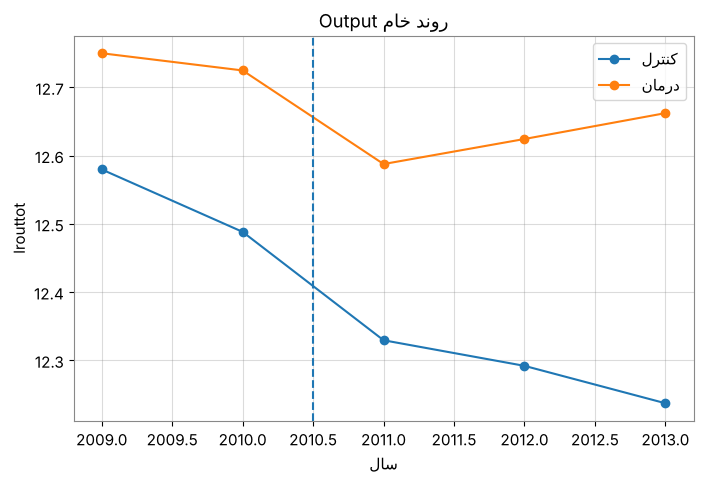

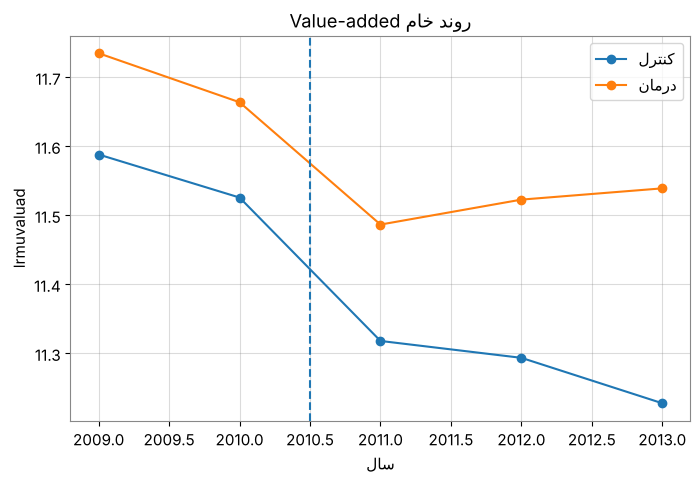

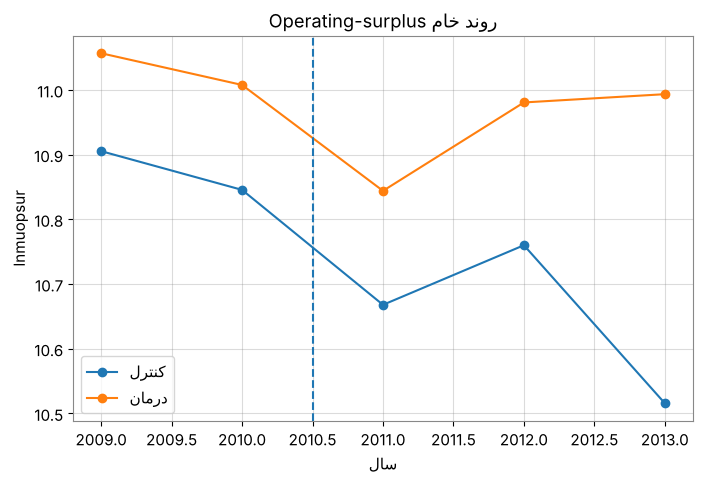

In [24]:

summary_by_year_treat = (
    df.groupby(["year", "treat_num"])[OUTCOMES]
    .mean()
    .reset_index()
)
display(summary_by_year_treat)

for outcome in OUTCOMES:
    plt.figure(figsize=(8, 5))
    for group, label in [(0, "کنترل"), (1, "درمان")]:
        temp = summary_by_year_treat[summary_by_year_treat["treat_num"] == group]
        plt.plot(temp["year"], temp[outcome], marker="o", label=label)
    plt.axvline(2010.5, linestyle="--")
    plt.title(f"روند خام {OUTCOME_LABELS[outcome]}")
    plt.xlabel("سال")
    plt.ylabel(outcome)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()



FIGURES


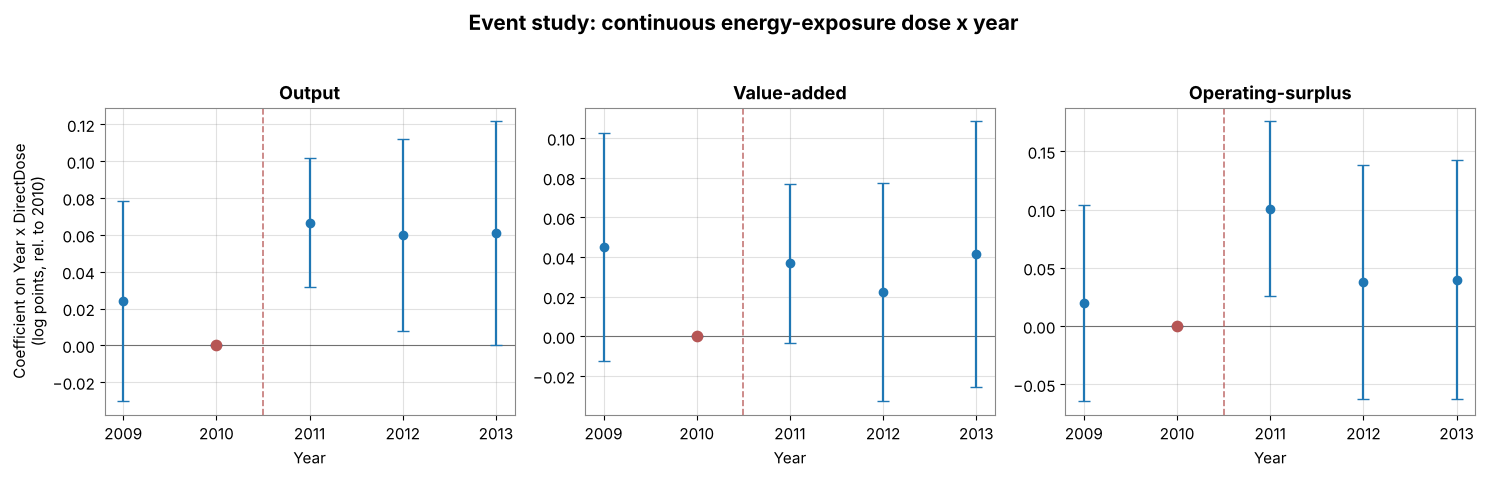

Saved fig1_event_study.png


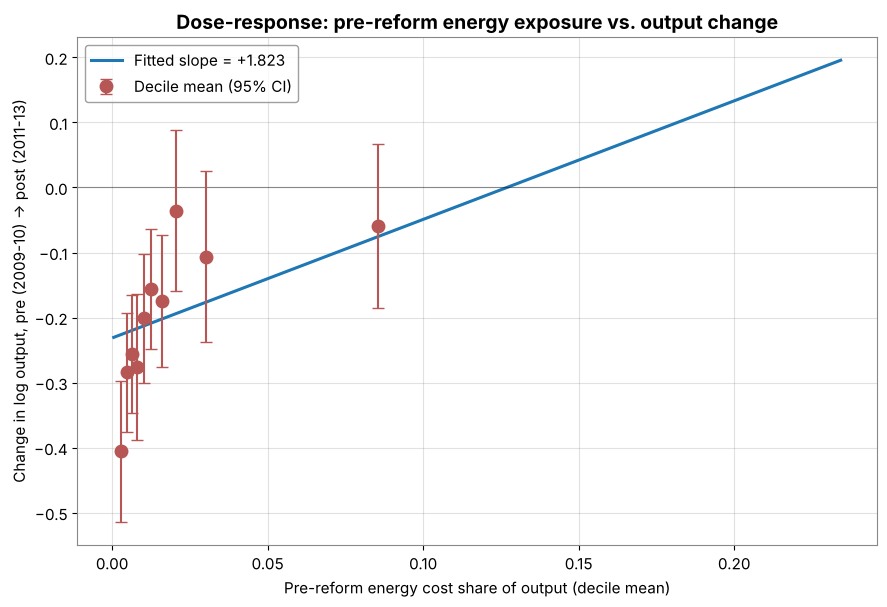

Saved fig2_dose_response.png


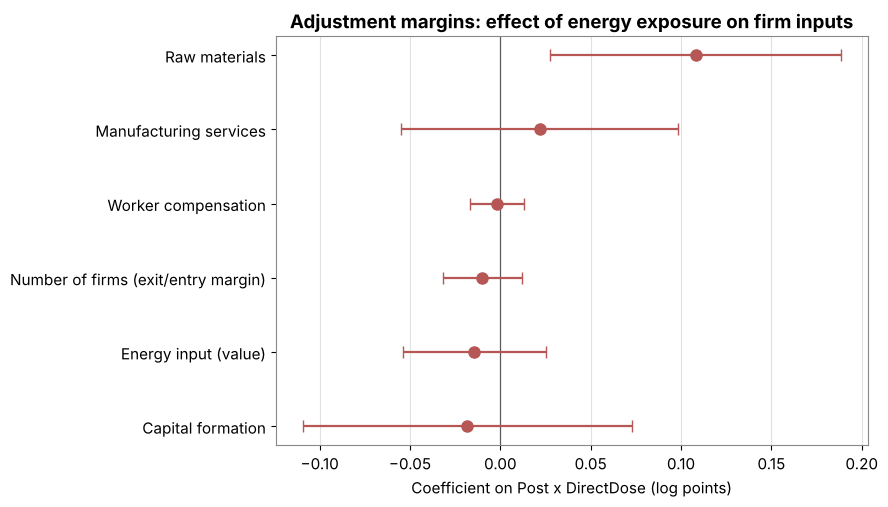

Saved fig3_adjustment_margins.png


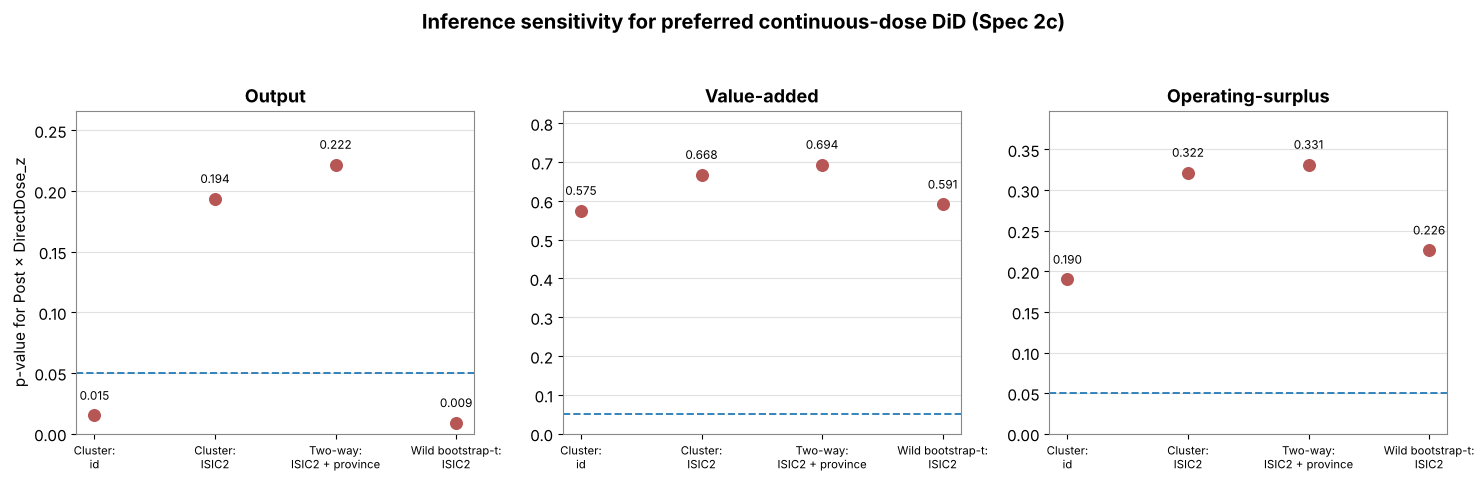

Saved fig4_inference.png


In [25]:
# =====================================================================
# FIGURES
# =====================================================================
log("\n" + "=" * 70)
log("FIGURES")
log("=" * 70)
try:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharex=True)
    for ax, oc in zip(axes, OUTCOMES):
        sub = event_df[event_df.outcome == oc].sort_values("year")
        years = sub["year"].to_numpy()
        coef = sub["coef"].to_numpy()
        yerr = np.vstack([coef - sub["ci_low"].to_numpy(), sub["ci_high"].to_numpy() - coef])
        ax.errorbar(years, coef, yerr=yerr, fmt="o", color=LINE_COLOR, ecolor=LINE_COLOR, elinewidth=1.6,
                    capsize=4, markersize=6, zorder=3)
        ax.scatter([2010], [0.0], color=DOT_COLOR, s=55, zorder=4)
        ax.axhline(0, color=TEXT_COLOR, linewidth=0.8, alpha=0.5)
        ax.axvline(2010.5, color=DOT_COLOR, linestyle="--", linewidth=1.2, alpha=0.8)
        ax.set_title(OUTCOME_LABELS[oc], fontsize=13, fontweight="bold", color=TEXT_COLOR)
        ax.set_xticks([2009, 2010, 2011, 2012, 2013])
        ax.grid(alpha=0.25)
        ax.set_xlabel("Year")
    axes[0].set_ylabel("Coefficient on Year x DirectDose\n(log points, rel. to 2010)")
    fig.suptitle("Event study: continuous energy-exposure dose x year", fontsize=15,
                 fontweight="bold", color=TEXT_COLOR, y=1.03)
    plt.tight_layout()
    plt.savefig("figures/fig1_event_study.png", dpi=200, bbox_inches="tight")
    plt.show()
    plt.close()
    log("Saved fig1_event_study.png")
except Exception as e:
    log(f"fig1 FAILED: {e}")

try:
    d = dfd_restricted.drop_duplicates("id").copy()
    unit_pre = dfd_restricted[dfd_restricted.year.isin([2009, 2010])].groupby("id")["lrouttot"].mean()
    unit_post = dfd_restricted[dfd_restricted.year.isin([2011, 2012, 2013])].groupby("id")["lrouttot"].mean()
    change = (unit_post - unit_pre).rename("delta_lrouttot")
    d = d.set_index("id").join(change, how="inner").reset_index().dropna(subset=["DirectDose_raw", "delta_lrouttot"])
    d["decile"] = pd.qcut(d["DirectDose_raw"], 10, labels=False, duplicates="drop") + 1
    bin_stats = d.groupby("decile").agg(mean_dose=("DirectDose_raw", "mean"),
                                          mean_change=("delta_lrouttot", "mean"),
                                          se_change=("delta_lrouttot", lambda s: s.std() / np.sqrt(len(s)))).reset_index()
    x, y = d["DirectDose_raw"].to_numpy(), d["delta_lrouttot"].to_numpy()
    coef_fit, *_ = np.linalg.lstsq(np.column_stack([np.ones_like(x), x]), y, rcond=None)
    xs = np.linspace(x.min(), x.max(), 100)
    fig, ax = plt.subplots(figsize=(9, 6.2))
    ax.errorbar(bin_stats["mean_dose"], bin_stats["mean_change"], yerr=1.96 * bin_stats["se_change"],
                fmt="o", color=DOT_COLOR, ecolor=DOT_COLOR, elinewidth=1.5, capsize=4, markersize=9, zorder=3,
                label="Decile mean (95% CI)")
    ax.plot(xs, coef_fit[0] + coef_fit[1] * xs, color=LINE_COLOR, linewidth=2.2, zorder=2,
            label=f"Fitted slope = {coef_fit[1]:+.3f}")
    ax.axhline(0, color=TEXT_COLOR, linewidth=0.8, alpha=0.4)
    ax.set_xlabel("Pre-reform energy cost share of output (decile mean)")
    ax.set_ylabel("Change in log output, pre (2009-10) -> post (2011-13)")
    ax.set_title("Dose-response: pre-reform energy exposure vs. output change", fontsize=14,
                 fontweight="bold", color=TEXT_COLOR)
    ax.legend(facecolor=AXES_BG, edgecolor=GRID_COLOR, labelcolor=TEXT_COLOR)
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.savefig("figures/fig2_dose_response.png", dpi=200, bbox_inches="tight")
    plt.show()
    plt.close()
    log("Saved fig2_dose_response.png")
except Exception as e:
    log(f"fig2 FAILED: {e}")

try:
    m = margins_df.dropna(subset=["coef"]).sort_values("coef")
    fig, ax = plt.subplots(figsize=(9, 5.2))
    y_pos = np.arange(len(m))
    ax.errorbar(m["coef"], y_pos, xerr=[m["coef"] - m["ci_low"], m["ci_high"] - m["coef"]],
                fmt="o", ecolor=DOT_COLOR, elinewidth=1.6, capsize=4, markersize=8, color=DOT_COLOR, zorder=3)
    ax.axvline(0, color=TEXT_COLOR, linewidth=0.9, alpha=0.6)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(m["outcome_label"])
    ax.set_xlabel("Coefficient on Post x DirectDose (log points)")
    ax.set_title("Adjustment margins: effect of energy exposure on firm inputs", fontsize=13.5,
                 fontweight="bold", color=TEXT_COLOR)
    ax.grid(alpha=0.25, axis="x")
    plt.tight_layout()
    plt.savefig("figures/fig3_adjustment_margins.png", dpi=200, bbox_inches="tight")
    plt.show()
    plt.close()
    log("Saved fig3_adjustment_margins.png")
except Exception as e:
    log(f"fig3 FAILED: {e}")

try:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))  # own y-axis per panel: p-value ranges differ a lot
    for ax, oc in zip(axes, OUTCOMES):
        row = inf_df[inf_df.outcome == oc].iloc[0]
        labels = ["Cluster:\nid", "Cluster:\nISIC2", "Two-way:\nISIC2 + province", "Wild bootstrap-t:\nISIC2"]
        pvals = [row["p_id"], row["p_isic2"], row["p_twoway"], row["p_wildboot"]]
        x_pos = np.arange(4)
        ax.scatter(x_pos, pvals, color=DOT_COLOR, s=70, zorder=3)
        ax.axhline(0.05, color=LINE_COLOR, linestyle="--", linewidth=1.4, alpha=0.9)
        ax.set_xticks(x_pos)
        ax.set_xticklabels(labels, fontsize=8.2)
        ax.set_title(OUTCOME_LABELS[oc], fontsize=13, fontweight="bold", color=TEXT_COLOR)
        ax.grid(alpha=0.25, axis="y")
        ymax = max(0.10, max(pvals) * 1.20)
        ax.set_ylim(0, min(1.0, ymax))
        for x, pval in zip(x_pos, pvals):
            ax.text(x, min(ymax * 0.95, pval + ymax * 0.04), f"{pval:.3f}",
                    ha="center", va="bottom", fontsize=8.5, color=TEXT_COLOR)
    axes[0].set_ylabel("p-value for Post × DirectDose_z")
    fig.suptitle("Inference sensitivity for preferred continuous-dose DiD (Spec 2c)",
                 fontsize=14.5, fontweight="bold", color=TEXT_COLOR, y=1.04)
    plt.tight_layout()
    plt.savefig("figures/fig4_inference.png", dpi=200, bbox_inches="tight")
    plt.show()
    plt.close()
    log("Saved fig4_inference.png")
except Exception as e:
    log(f"fig4 FAILED: {e}")


### Export workbook

Collects every results table (and the console log) into a single `extension_results.xlsx` workbook.

In [26]:
# =====================================================================
# EXPORT WORKBOOK
# =====================================================================
log("\n" + "=" * 70)
log("EXPORTING WORKBOOK")
log("=" * 70)

required_result_sheets = [
    "00_data_audit", "01_replication_gate", "02_total_vs_conditional", "03_dose_did",
    "04_event_study", "05_inference_comparison", "06_horse_race", "07_adjustment_margins",
    "08a_restricted_sample_robustness", "08b_rank_vs_standardized_dose",
    "08c_complete_pre_robustness", "09b_dose_sanity_checks",
]
missing_result_sheets = [name for name in required_result_sheets if name not in sheets]
if missing_result_sheets:
    raise RuntimeError(f"Cannot export a complete workbook; missing result sheets: {missing_result_sheets}")

sheets["09_metadata"] = pd.DataFrame([
    {"key": "estimator", "value": "Within-transformed OLS, id FE absorbed, Stata areg-style clustered SE"},
    {"key": "stats_engine", "value": "stats_lite.py (numpy + pandas + mpmath)"},
    {"key": "replication_gate", "value": "PASSED" if gate_pass else "FAILED"},
    {"key": "n_obs_full_sample", "value": int(len(df))},
    {"key": "n_obs_dose_restricted", "value": int(len(dfd_restricted))},
    {"key": "direct_dose_definition", "value": "mean 2009-2010 energy cost share of output"},
    {"key": "indirect_dose_definition", "value": "mean 2009-2010 (materials + packaging + tools) cost share of output"},
    {"key": "indirect_dose_interpretation", "value": "proxy for dependence on intermediate inputs; not direct upstream supplier energy intensity"},
    {"key": "preferred_specification", "value": "Spec 2c: unit FE + ISIC2×year FE + province×year FE"},
    {"key": "inference_comparison_focal", "value": "Post × DirectDose_z in preferred Spec 2c"},
])
sheets["10_console_log"] = pd.DataFrame({"log": log_lines})

with pd.ExcelWriter(OUT_XLSX, engine="openpyxl") as writer:
    order = ["00_data_audit", "01_replication_gate", "02_total_vs_conditional", "03_dose_did",
             "04_event_study", "05_inference_comparison", "06_horse_race", "07_adjustment_margins",
             "08a_restricted_sample_robustness", "08b_rank_vs_standardized_dose",
             "08c_complete_pre_robustness", "09_metadata", "09b_dose_sanity_checks", "10_console_log"]
    for name in order:
        sheets[name].to_excel(writer, sheet_name=name[:31], index=False)

log(f"\nSaved {OUT_XLSX}")
log("\nDONE.")



EXPORTING WORKBOOK

Saved results/extension_results.xlsx

DONE.


## Reproducibility notes

- **Fail-fast checks:** Step 0 raises a clear exception if required columns or years are missing, `(id, year)` observations are duplicated, the `id` decomposition is inconsistent, or the replication gate fails.
- **Random seed:** the wild cluster bootstrap in Step 5 uses `RNG = np.random.default_rng(20260815)`, so a full top-to-bottom run reproduces the same bootstrap draws.
- **File paths:** the notebook reads `data/mydata.xlsx` and writes `results/python_regression_results.xlsx` and `results/extension_results.xlsx`.
- **Figures:** `fig1_event_study.png`, `fig2_dose_response.png`, `fig3_adjustment_margins.png`, and `fig4_inference.png` are saved in `figures/` and displayed inline.
- **Interpretation:** `IndirectDose` is an intermediate-input dependence proxy. It does not directly observe the energy intensity of upstream suppliers. The event-study design has one pre-reform contrast (2009 relative to 2010), so it provides only a limited pre-trend diagnostic.
